<a href="https://colab.research.google.com/github/marviiiin/Computer-Vision/blob/main/DL4CV_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import cv2
import tensorflow as tf
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from google.colab.patches import cv2_imshow

9
torch.Size([3, 3, 224, 224]) torch.Size([3, 1, 224, 224])


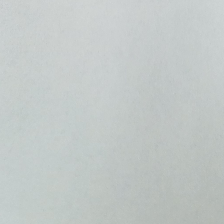

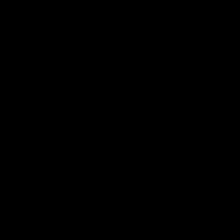

In [ ]:
class Coins(torch.utils.data.Dataset):
    def __init__(self, path, mode):
        self.path = path
        self.images = sorted([x for x in os.listdir(path) if x.endswith('.png')])
        self.mode = mode

        self.t_train = transforms.Compose([
            #transforms.RandomHorizontalFlip(p=0.5),
            #transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
            #transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
            torchvision.transforms.RandomCrop((224,224))
        ])
        #self.t_not_train = transforms.Compose([
        #    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        #    torchvision.transforms.RandomCrop(size
        #])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = cv2.imread(os.path.join(self.path, self.images[idx]), cv2.IMREAD_COLOR)
        img = cv2.resize(img, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_LINEAR)
        #cv2_imshow(img)
        img = img/255.0
        img = np.transpose(img, (2,0,1)).astype(np.float32)
        img = torch.from_numpy(img)

        with open(os.path.join(self.path, self.images[idx].replace('.png', '.txt')), 'r') as fp:
            lines = fp.readlines()

        mask = np.zeros((img.size(1), img.size(2)), np.uint8)
        for line in lines[1:]:
            x, y, _, r = [int(x) for x in line.split()]
            x = int(x*0.25+0.5)
            y = int(y*0.25+0.5)
            r = int(r*0.25+0.5)
            cv2.circle(mask, (x, y), r, (255,255,255), -1)

        #cv2_imshow(mask)
        mask = mask/255.0
        mask = mask[np.newaxis].astype(np.float32)
        mask = torch.from_numpy(mask)

        tmp = torch.vstack([img, mask])
        #print(tmp.size(), tmp.type())

        if self.mode == 'train':
          tmp = self.t_train(tmp)

        img = tmp[:3]
        mask = tmp[3:]

        #print(img.size(), img.type(), mask.size(), mask.type())

        #if self.mode == 'train':
        #  img = self.t_train(img)
        #else:
        #  img = self.t_not_train(img)

        return img, mask

train_dataset = Coins('/content/drive/MyDrive/ComputerVision/coins', 'train')
print(len(train_dataset))
#val_dataset = CIFAR(x_train[4000:], y_train[4000:], 'val')
train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=3, shuffle=True)
#val_dataloader = torch.utils.data.DataLoader(val_dataset, batch_size=100, shuffle=False)

for x, y in train_dataloader:
  print(x.shape, y.shape)

  cv2_imshow(x[0].numpy().transpose((1,2,0))*255.0)
  cv2_imshow(y[0,0].numpy()*255.0)

  break

0 0.6609634160995483 tensor(0.) tensor(1.) tensor(0.4180, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5498, device='cuda:0', grad_fn=<MaxBackward1>)


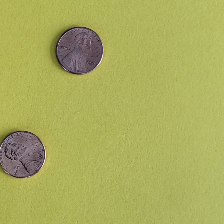

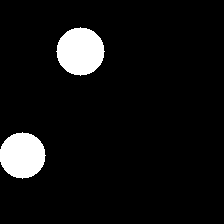

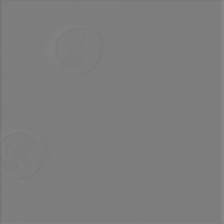

1 0.6143628358840942 tensor(0.) tensor(1.) tensor(0.3794, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5383, device='cuda:0', grad_fn=<MaxBackward1>)


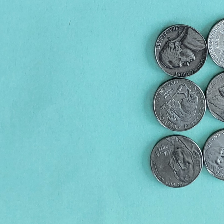

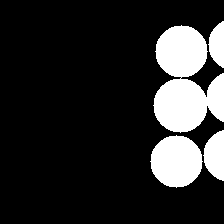

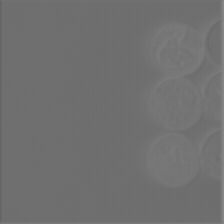

2 0.5386170744895935 tensor(0.) tensor(1.) tensor(0.3246, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5250, device='cuda:0', grad_fn=<MaxBackward1>)


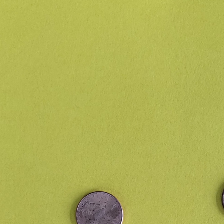

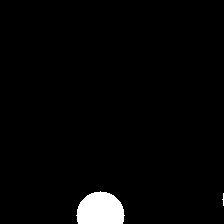

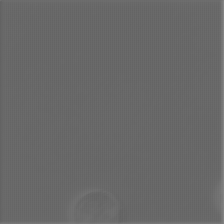

3 0.3886379301548004 tensor(0.) tensor(1.) tensor(0.1168, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5055, device='cuda:0', grad_fn=<MaxBackward1>)


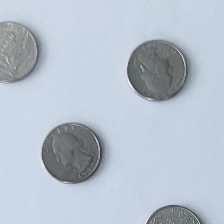

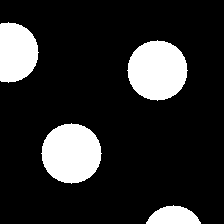

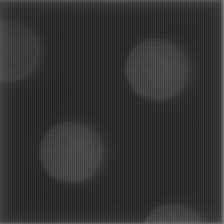

4 0.5941057205200195 tensor(0.) tensor(1.) tensor(0.0010, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4864, device='cuda:0', grad_fn=<MaxBackward1>)


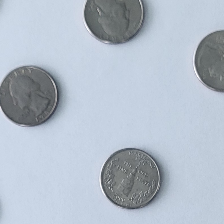

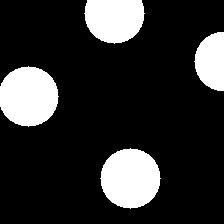

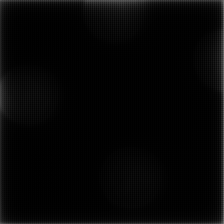

5 0.33370620012283325 tensor(0.) tensor(1.) tensor(0.0135, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4807, device='cuda:0', grad_fn=<MaxBackward1>)


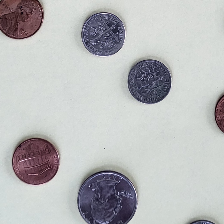

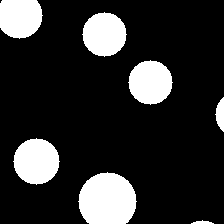

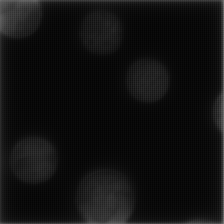

6 0.31778842210769653 tensor(0.) tensor(1.) tensor(0.0629, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4929, device='cuda:0', grad_fn=<MaxBackward1>)


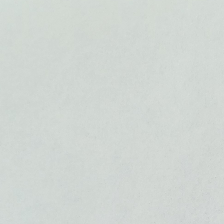

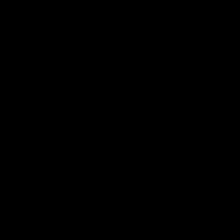

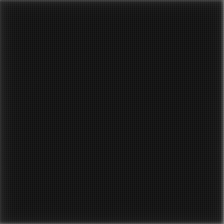

7 0.23288266360759735 tensor(0.) tensor(1.) tensor(0.0741, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4802, device='cuda:0', grad_fn=<MaxBackward1>)


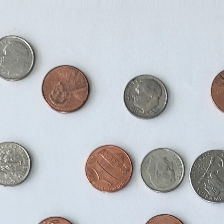

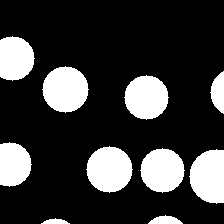

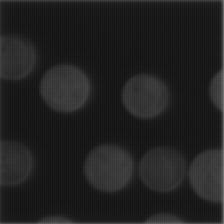

8 0.3203050494194031 tensor(0.) tensor(1.) tensor(0.0737, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4800, device='cuda:0', grad_fn=<MaxBackward1>)


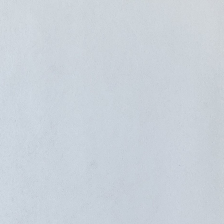

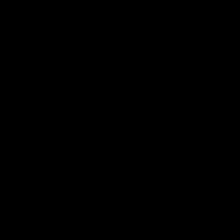

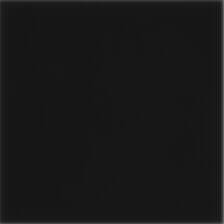

9 0.14918406307697296 tensor(0.) tensor(1.) tensor(0.0623, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4716, device='cuda:0', grad_fn=<MaxBackward1>)


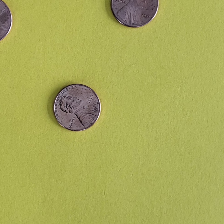

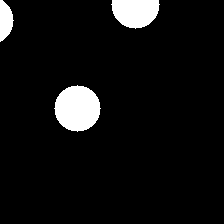

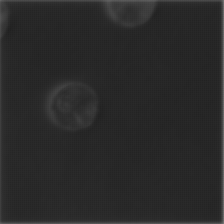

10 0.38091278076171875 tensor(0.) tensor(1.) tensor(0.0390, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4671, device='cuda:0', grad_fn=<MaxBackward1>)


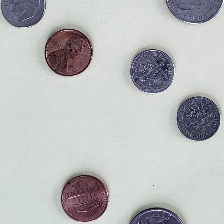

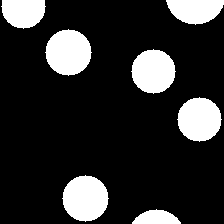

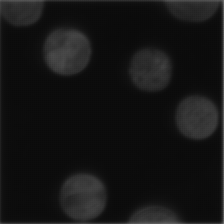

11 0.41819533705711365 tensor(0.) tensor(1.) tensor(0.0309, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4688, device='cuda:0', grad_fn=<MaxBackward1>)


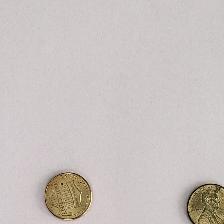

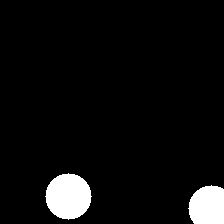

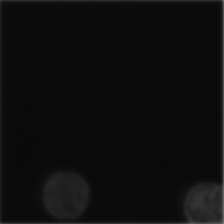

12 0.1537872552871704 tensor(0.) tensor(1.) tensor(0.0278, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4427, device='cuda:0', grad_fn=<MaxBackward1>)


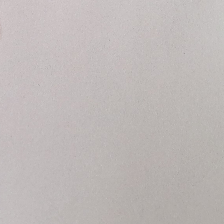

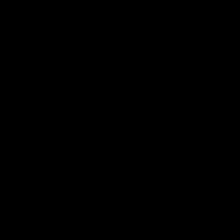

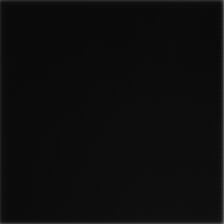

13 0.20393002033233643 tensor(0.) tensor(1.) tensor(0.0268, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4518, device='cuda:0', grad_fn=<MaxBackward1>)


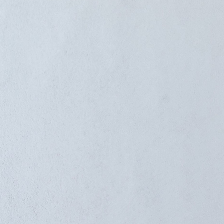

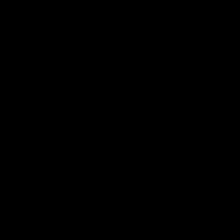

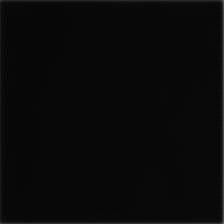

14 0.29576897621154785 tensor(0.) tensor(1.) tensor(0.0257, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4507, device='cuda:0', grad_fn=<MaxBackward1>)


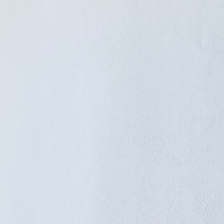

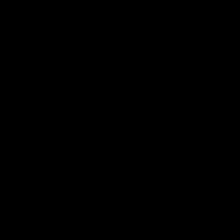

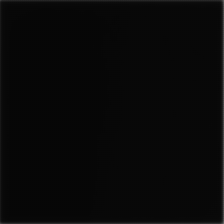

15 0.3583761751651764 tensor(0.) tensor(1.) tensor(0.0311, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4373, device='cuda:0', grad_fn=<MaxBackward1>)


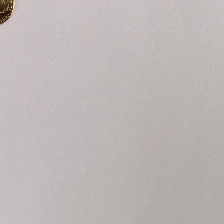

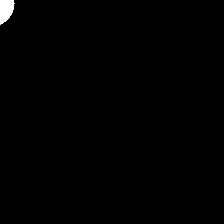

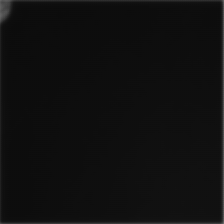

16 0.3384086787700653 tensor(0.) tensor(1.) tensor(0.0528, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4501, device='cuda:0', grad_fn=<MaxBackward1>)


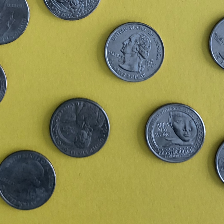

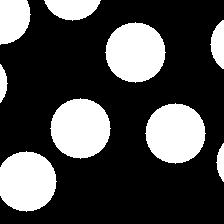

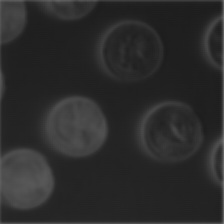

17 0.45465895533561707 tensor(0.) tensor(1.) tensor(0.0435, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4497, device='cuda:0', grad_fn=<MaxBackward1>)


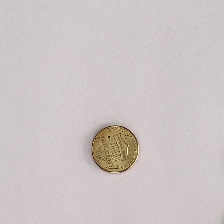

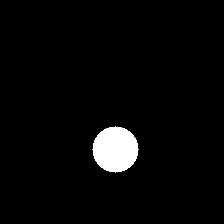

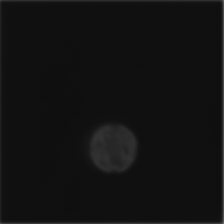

18 0.2255866378545761 tensor(0.) tensor(1.) tensor(0.0543, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4264, device='cuda:0', grad_fn=<MaxBackward1>)


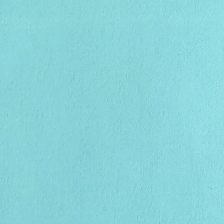

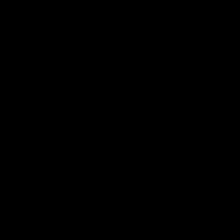

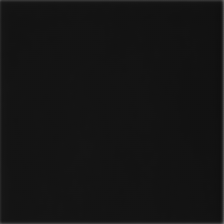

19 0.35111454129219055 tensor(0.) tensor(1.) tensor(0.0592, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4335, device='cuda:0', grad_fn=<MaxBackward1>)


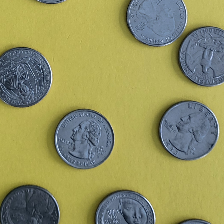

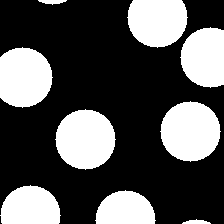

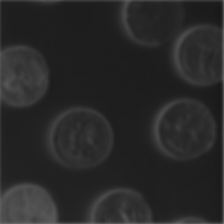

20 0.2595997452735901 tensor(0.) tensor(1.) tensor(0.0383, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4742, device='cuda:0', grad_fn=<MaxBackward1>)


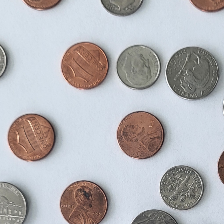

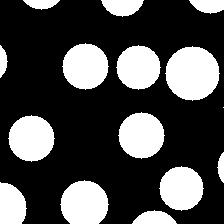

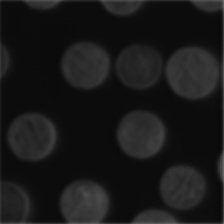

21 0.1412300318479538 tensor(0.) tensor(1.) tensor(0.0418, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4576, device='cuda:0', grad_fn=<MaxBackward1>)


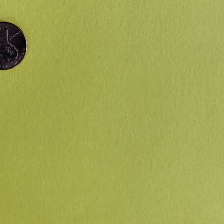

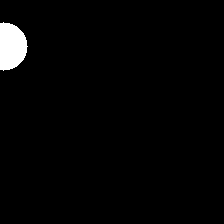

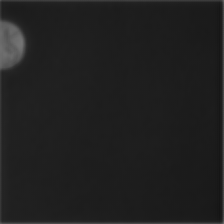

22 0.09632114320993423 tensor(0.) tensor(1.) tensor(0.0279, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.3958, device='cuda:0', grad_fn=<MaxBackward1>)


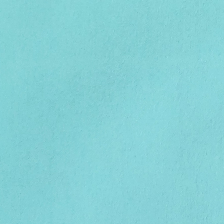

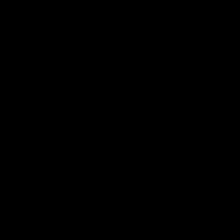

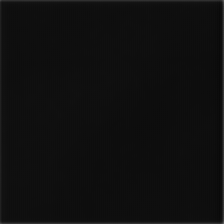

23 0.22093529999256134 tensor(0.) tensor(1.) tensor(0.0206, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4166, device='cuda:0', grad_fn=<MaxBackward1>)


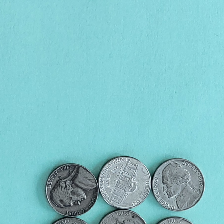

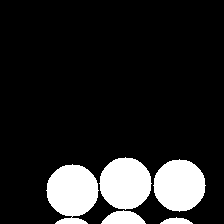

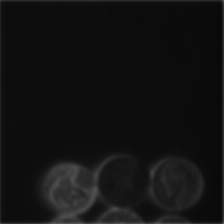

24 0.3624490797519684 tensor(0.) tensor(1.) tensor(0.0100, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4331, device='cuda:0', grad_fn=<MaxBackward1>)


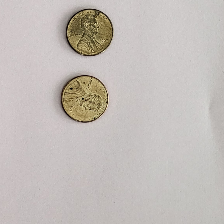

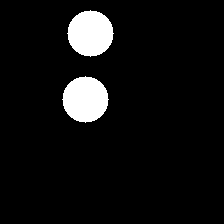

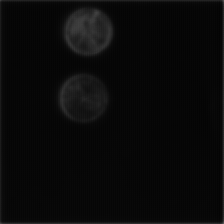

25 0.32696911692619324 tensor(0.) tensor(1.) tensor(0.0147, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4215, device='cuda:0', grad_fn=<MaxBackward1>)


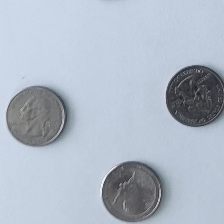

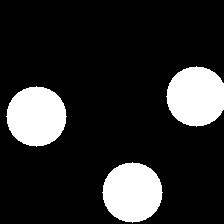

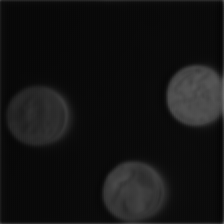

26 0.1936158835887909 tensor(0.) tensor(1.) tensor(0.0096, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4613, device='cuda:0', grad_fn=<MaxBackward1>)


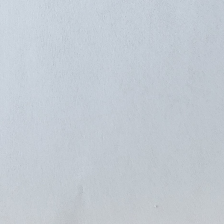

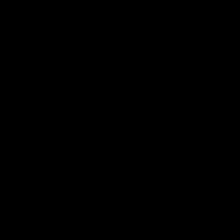

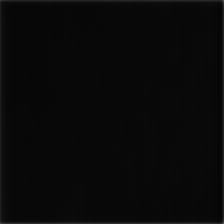

27 0.2518867254257202 tensor(0.) tensor(1.) tensor(0.0075, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4369, device='cuda:0', grad_fn=<MaxBackward1>)


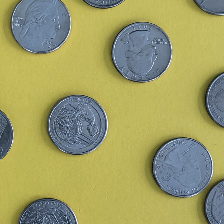

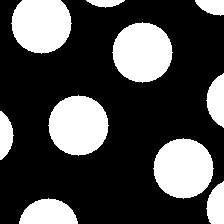

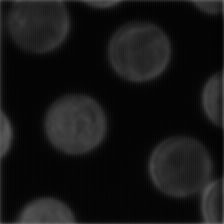

28 0.1399419903755188 tensor(0.) tensor(1.) tensor(0.0153, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4430, device='cuda:0', grad_fn=<MaxBackward1>)


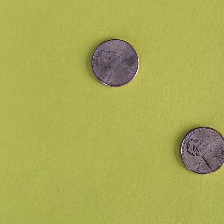

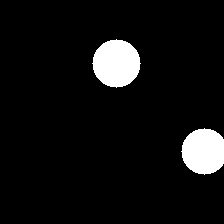

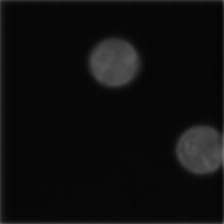

29 0.26939278841018677 tensor(0.) tensor(1.) tensor(0.0030, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4608, device='cuda:0', grad_fn=<MaxBackward1>)


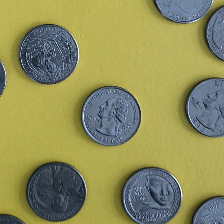

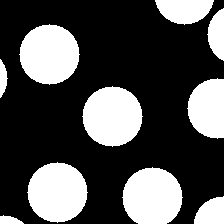

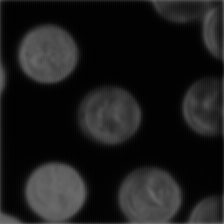

30 0.15402622520923615 tensor(0.) tensor(1.) tensor(0.0079, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4190, device='cuda:0', grad_fn=<MaxBackward1>)


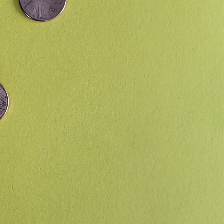

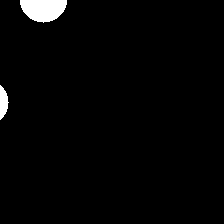

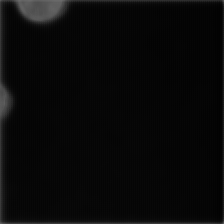

31 0.26388752460479736 tensor(0.) tensor(1.) tensor(0.0010, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5130, device='cuda:0', grad_fn=<MaxBackward1>)


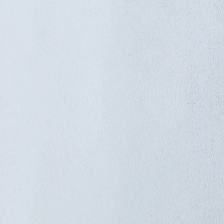

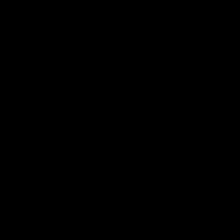

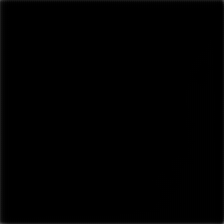

32 0.18634586036205292 tensor(0.) tensor(1.) tensor(0.0057, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5033, device='cuda:0', grad_fn=<MaxBackward1>)


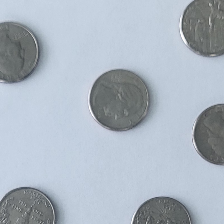

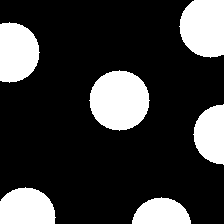

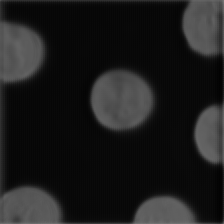

33 0.14545896649360657 tensor(0.) tensor(1.) tensor(0.0014, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4810, device='cuda:0', grad_fn=<MaxBackward1>)


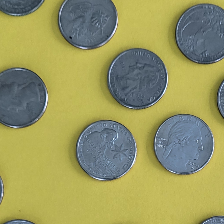

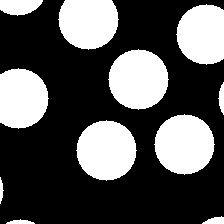

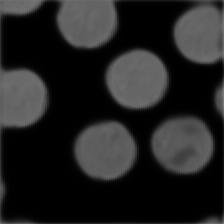

34 0.17306087911128998 tensor(0.) tensor(1.) tensor(0.0004, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5123, device='cuda:0', grad_fn=<MaxBackward1>)


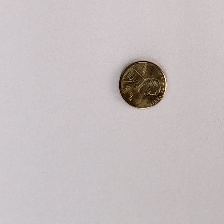

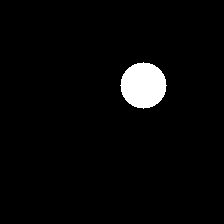

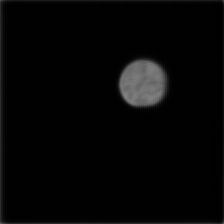

35 0.19851383566856384 tensor(0.) tensor(1.) tensor(0.0013, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5329, device='cuda:0', grad_fn=<MaxBackward1>)


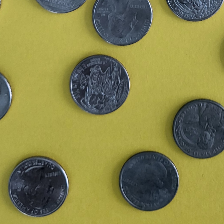

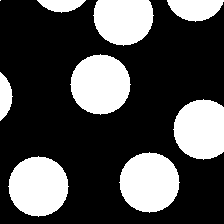

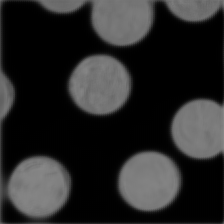

36 0.1093868836760521 tensor(0.) tensor(1.) tensor(0.0002, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5200, device='cuda:0', grad_fn=<MaxBackward1>)


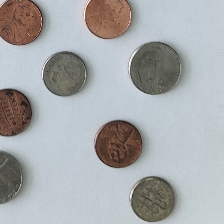

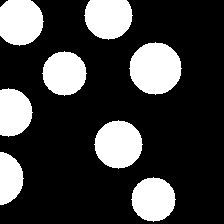

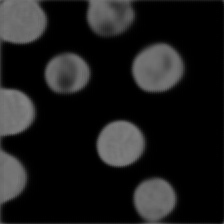

37 0.026447875425219536 tensor(0.) tensor(1.) tensor(0.0017, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5452, device='cuda:0', grad_fn=<MaxBackward1>)


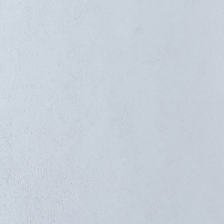

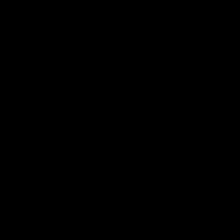

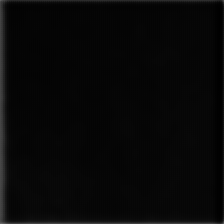

38 0.14666493237018585 tensor(0.) tensor(1.) tensor(7.0728e-05, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5536, device='cuda:0', grad_fn=<MaxBackward1>)


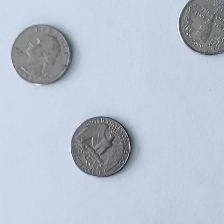

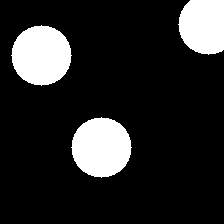

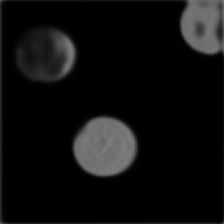

39 0.058554746210575104 tensor(0.) tensor(1.) tensor(0.0002, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5112, device='cuda:0', grad_fn=<MaxBackward1>)


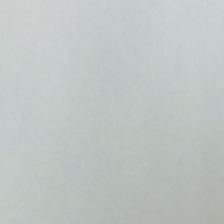

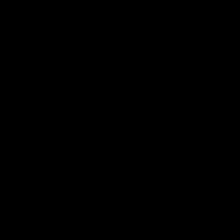

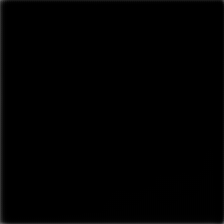

40 0.10566563159227371 tensor(0.) tensor(1.) tensor(0.0006, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5806, device='cuda:0', grad_fn=<MaxBackward1>)


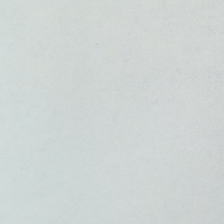

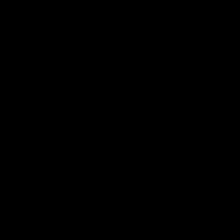

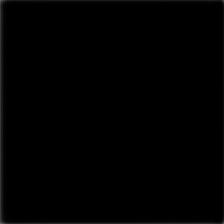

41 0.15394628047943115 tensor(0.) tensor(1.) tensor(1.8661e-05, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5828, device='cuda:0', grad_fn=<MaxBackward1>)


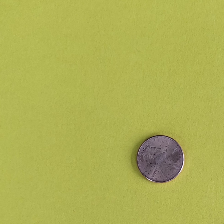

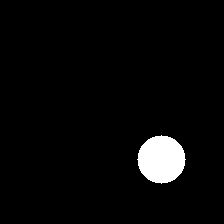

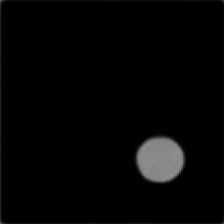

42 0.11256449669599533 tensor(0.) tensor(1.) tensor(0.0001, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.6167, device='cuda:0', grad_fn=<MaxBackward1>)


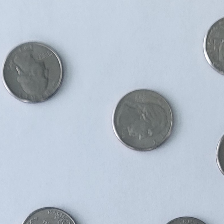

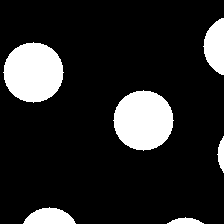

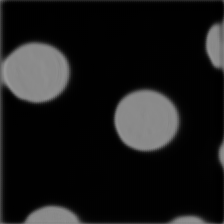

43 0.009988978505134583 tensor(0.) tensor(1.) tensor(5.9570e-05, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.5659, device='cuda:0', grad_fn=<MaxBackward1>)


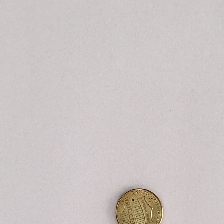

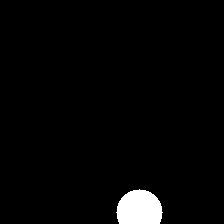

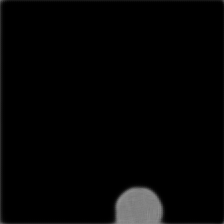

44 0.12043193727731705 tensor(0.) tensor(1.) tensor(0.0031, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.6699, device='cuda:0', grad_fn=<MaxBackward1>)


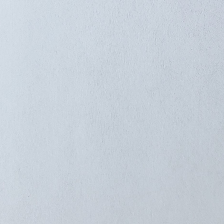

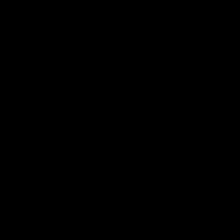

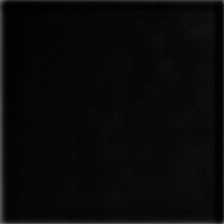

45 0.1233830600976944 tensor(0.) tensor(1.) tensor(1.0272e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.6736, device='cuda:0', grad_fn=<MaxBackward1>)


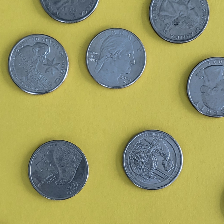

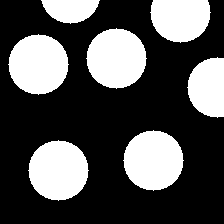

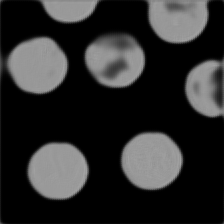

46 0.14242982864379883 tensor(0.) tensor(1.) tensor(8.3382e-05, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7200, device='cuda:0', grad_fn=<MaxBackward1>)


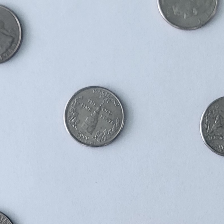

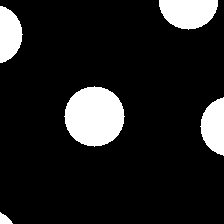

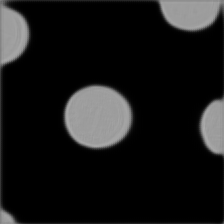

47 0.09602965414524078 tensor(0.) tensor(1.) tensor(5.4618e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7004, device='cuda:0', grad_fn=<MaxBackward1>)


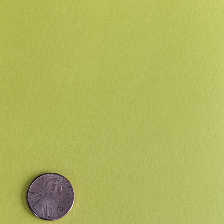

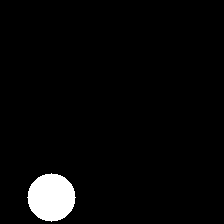

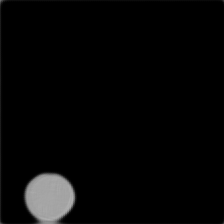

48 0.17500759661197662 tensor(0.) tensor(1.) tensor(2.5760e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7208, device='cuda:0', grad_fn=<MaxBackward1>)


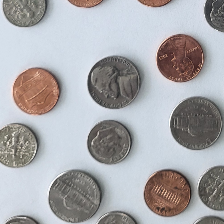

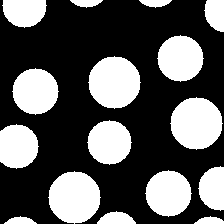

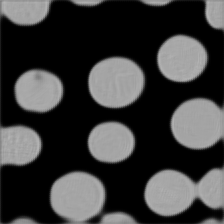

49 0.09964735060930252 tensor(0.) tensor(1.) tensor(1.6526e-05, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7740, device='cuda:0', grad_fn=<MaxBackward1>)


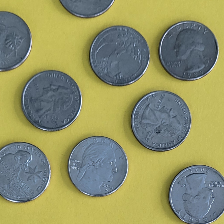

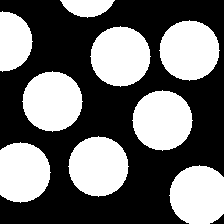

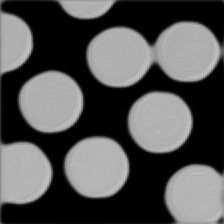

50 0.08962810039520264 tensor(0.) tensor(1.) tensor(1.4023e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7831, device='cuda:0', grad_fn=<MaxBackward1>)


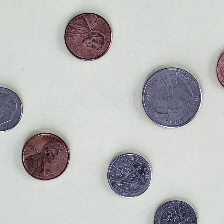

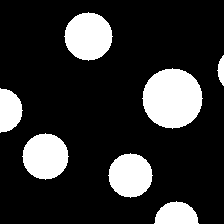

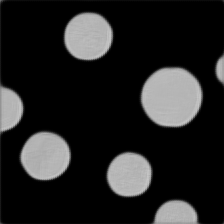

51 0.05851404368877411 tensor(0.) tensor(1.) tensor(0.0002, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.8417, device='cuda:0', grad_fn=<MaxBackward1>)


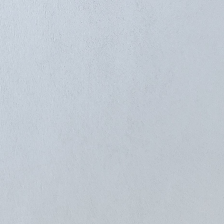

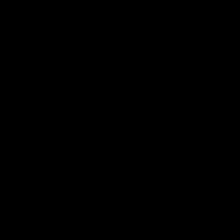

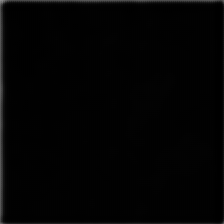

52 0.10346207022666931 tensor(0.) tensor(1.) tensor(1.3403e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.8309, device='cuda:0', grad_fn=<MaxBackward1>)


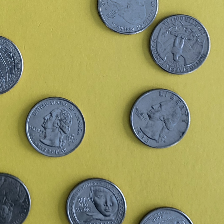

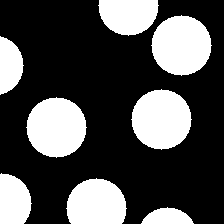

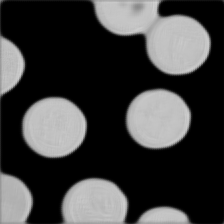

53 0.0057166991755366325 tensor(0.) tensor(1.) tensor(1.7122e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.8421, device='cuda:0', grad_fn=<MaxBackward1>)


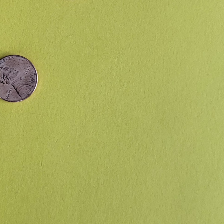

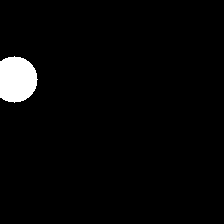

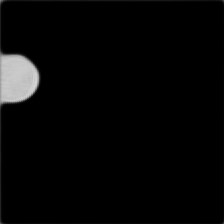

54 0.07944165170192719 tensor(0.) tensor(1.) tensor(8.2322e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.8526, device='cuda:0', grad_fn=<MaxBackward1>)


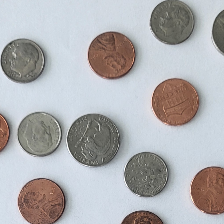

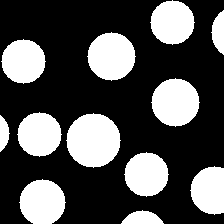

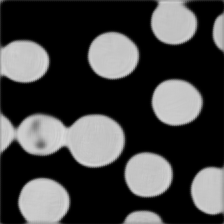

55 0.026207629591226578 tensor(0.) tensor(1.) tensor(9.0227e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.8912, device='cuda:0', grad_fn=<MaxBackward1>)


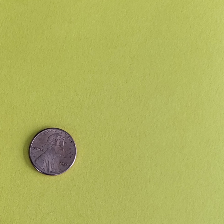

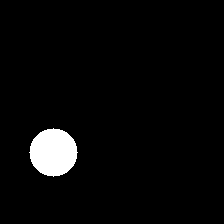

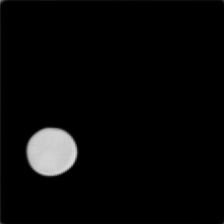

56 0.03157805651426315 tensor(0.) tensor(1.) tensor(7.3862e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9256, device='cuda:0', grad_fn=<MaxBackward1>)


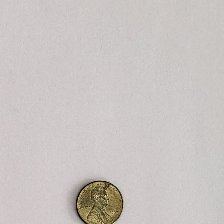

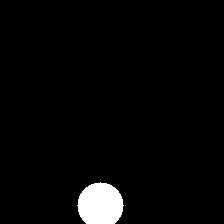

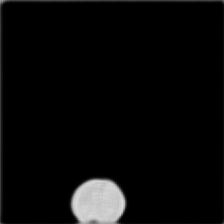

57 0.03339674323797226 tensor(0.) tensor(1.) tensor(3.0161e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.8797, device='cuda:0', grad_fn=<MaxBackward1>)


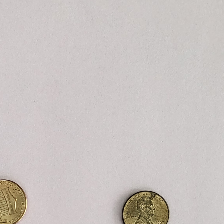

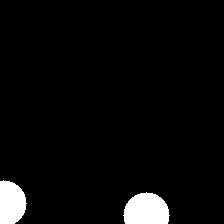

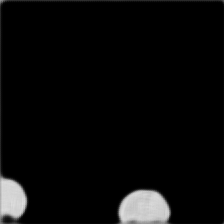

58 0.02518046461045742 tensor(0.) tensor(1.) tensor(1.0653e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.8841, device='cuda:0', grad_fn=<MaxBackward1>)


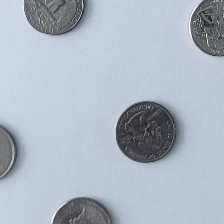

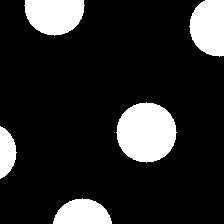

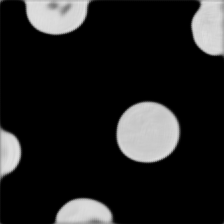

59 0.1093631237745285 tensor(0.) tensor(1.) tensor(3.8834e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9515, device='cuda:0', grad_fn=<MaxBackward1>)


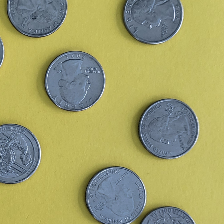

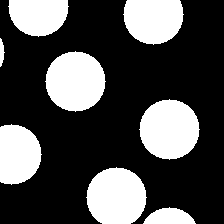

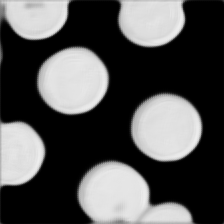

60 0.01352357491850853 tensor(0.) tensor(1.) tensor(1.5553e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9305, device='cuda:0', grad_fn=<MaxBackward1>)


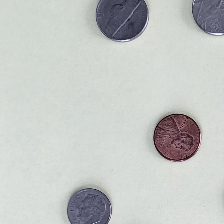

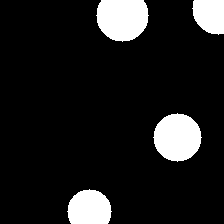

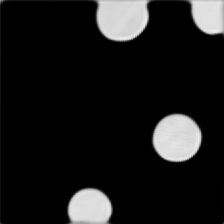

61 0.05291788652539253 tensor(0.) tensor(1.) tensor(1.1753e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9297, device='cuda:0', grad_fn=<MaxBackward1>)


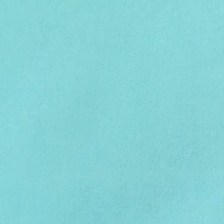

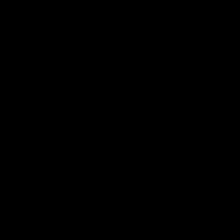

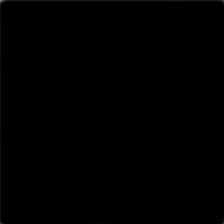

62 0.07441463321447372 tensor(0.) tensor(1.) tensor(1.7725e-05, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9432, device='cuda:0', grad_fn=<MaxBackward1>)


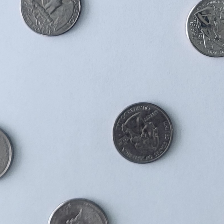

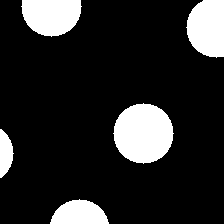

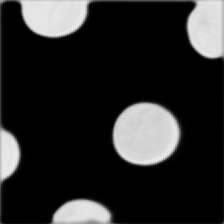

63 0.044277772307395935 tensor(0.) tensor(1.) tensor(4.5716e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9400, device='cuda:0', grad_fn=<MaxBackward1>)


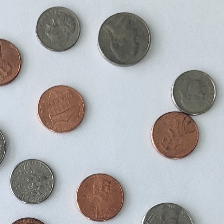

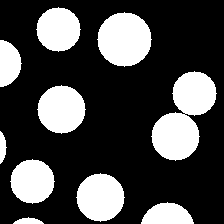

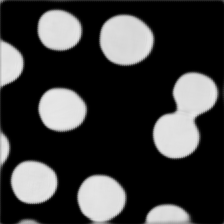

64 0.040030587464571 tensor(0.) tensor(1.) tensor(5.0056e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9534, device='cuda:0', grad_fn=<MaxBackward1>)


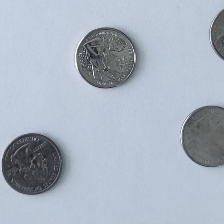

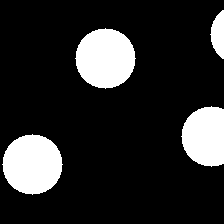

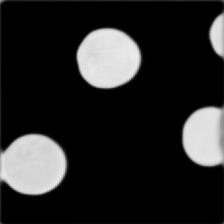

65 0.029229117557406425 tensor(0.) tensor(1.) tensor(1.4666e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9664, device='cuda:0', grad_fn=<MaxBackward1>)


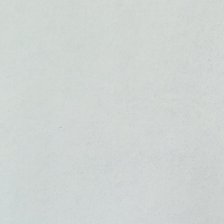

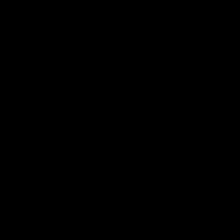

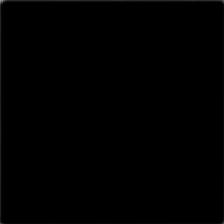

66 0.054970961064100266 tensor(0.) tensor(1.) tensor(4.7443e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9293, device='cuda:0', grad_fn=<MaxBackward1>)


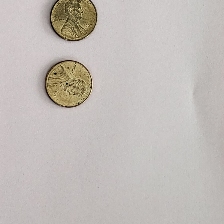

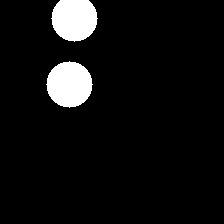

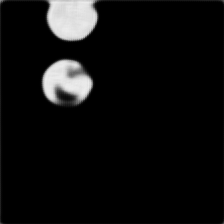

67 0.03157232701778412 tensor(0.) tensor(1.) tensor(7.8396e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9493, device='cuda:0', grad_fn=<MaxBackward1>)


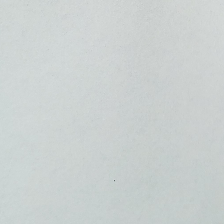

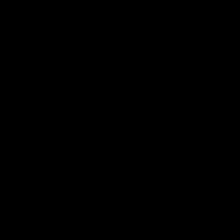

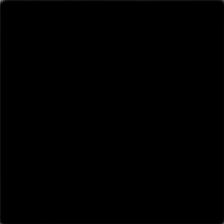

68 0.0770125612616539 tensor(0.) tensor(1.) tensor(2.6682e-05, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9703, device='cuda:0', grad_fn=<MaxBackward1>)


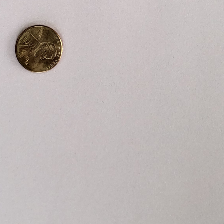

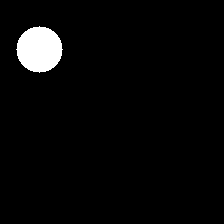

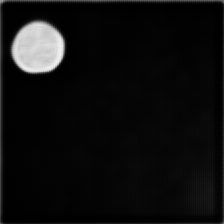

69 0.03864617645740509 tensor(0.) tensor(1.) tensor(1.9074e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9315, device='cuda:0', grad_fn=<MaxBackward1>)


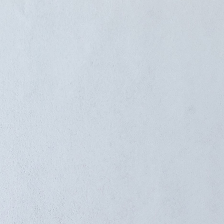

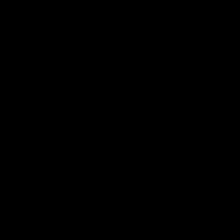

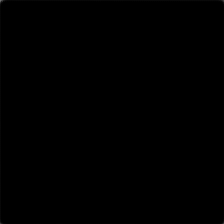

70 0.04209025949239731 tensor(0.) tensor(1.) tensor(2.6892e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9667, device='cuda:0', grad_fn=<MaxBackward1>)


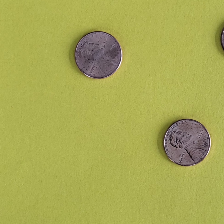

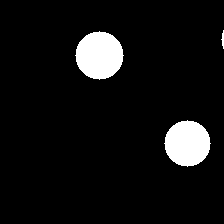

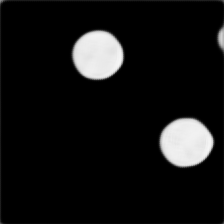

71 0.053387511521577835 tensor(0.) tensor(1.) tensor(1.1384e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9639, device='cuda:0', grad_fn=<MaxBackward1>)


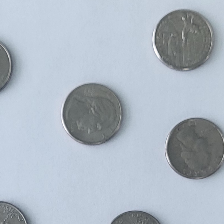

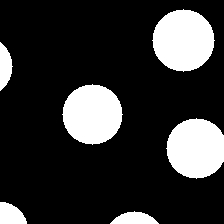

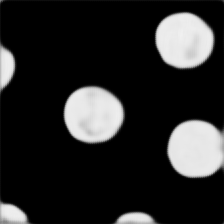

72 0.03425338864326477 tensor(0.) tensor(1.) tensor(5.5328e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9690, device='cuda:0', grad_fn=<MaxBackward1>)


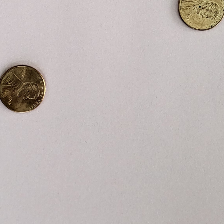

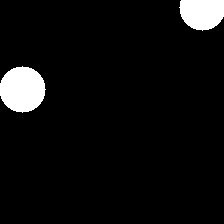

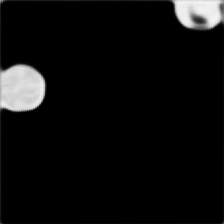

73 0.03994925692677498 tensor(0.) tensor(1.) tensor(7.2588e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9797, device='cuda:0', grad_fn=<MaxBackward1>)


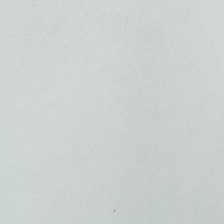

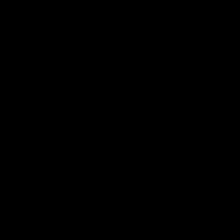

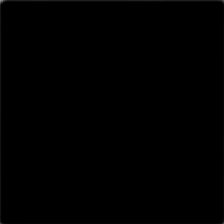

74 0.047651004046201706 tensor(0.) tensor(1.) tensor(7.9139e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9601, device='cuda:0', grad_fn=<MaxBackward1>)


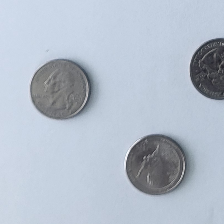

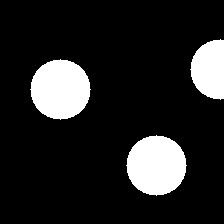

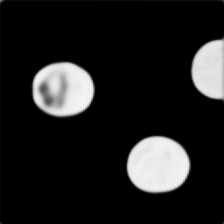

75 0.05216967687010765 tensor(0.) tensor(1.) tensor(1.4806e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9799, device='cuda:0', grad_fn=<MaxBackward1>)


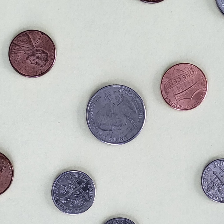

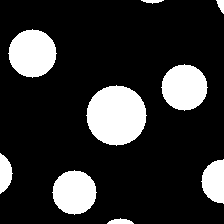

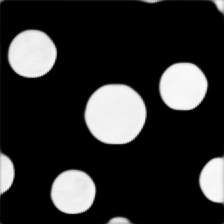

76 0.06509701162576675 tensor(0.) tensor(1.) tensor(3.2351e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9841, device='cuda:0', grad_fn=<MaxBackward1>)


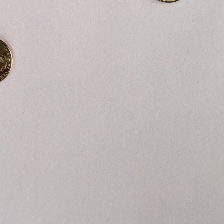

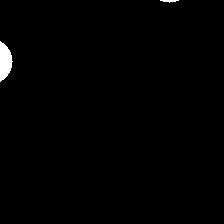

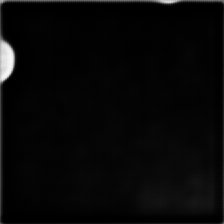

77 0.13077393174171448 tensor(0.) tensor(1.) tensor(2.0622e-10, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9657, device='cuda:0', grad_fn=<MaxBackward1>)


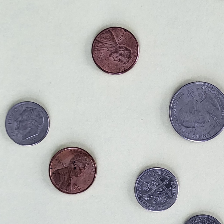

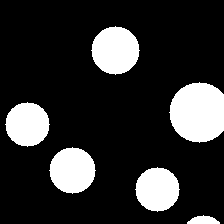

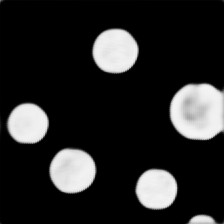

78 0.03796817362308502 tensor(0.) tensor(1.) tensor(1.9814e-05, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9735, device='cuda:0', grad_fn=<MaxBackward1>)


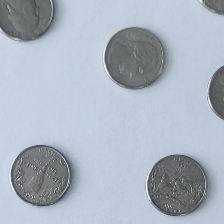

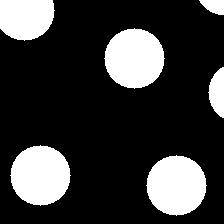

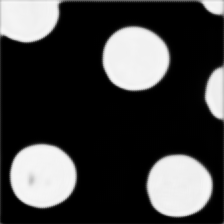

79 0.008683210238814354 tensor(0.) tensor(1.) tensor(5.1942e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9680, device='cuda:0', grad_fn=<MaxBackward1>)


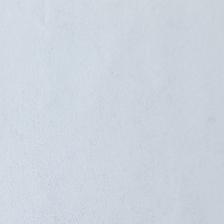

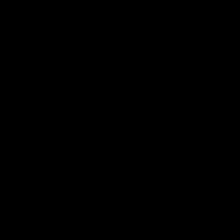

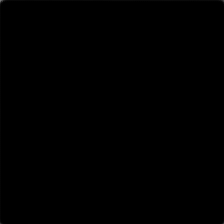

80 0.006959159392863512 tensor(0.) tensor(1.) tensor(3.7449e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9671, device='cuda:0', grad_fn=<MaxBackward1>)


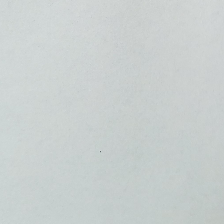

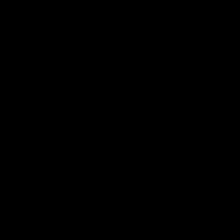

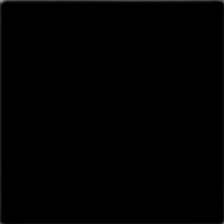

81 0.04643658176064491 tensor(0.) tensor(1.) tensor(3.7047e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9492, device='cuda:0', grad_fn=<MaxBackward1>)


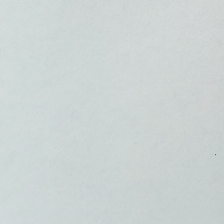

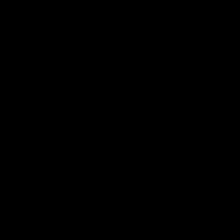

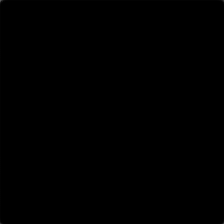

82 0.07602451741695404 tensor(0.) tensor(1.) tensor(2.9610e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9593, device='cuda:0', grad_fn=<MaxBackward1>)


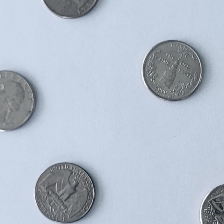

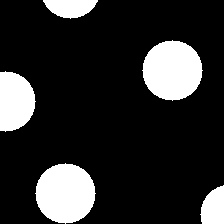

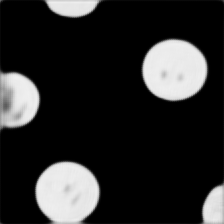

83 0.7924013137817383 tensor(0.) tensor(1.) tensor(1.2138e-16, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9088, device='cuda:0', grad_fn=<MaxBackward1>)


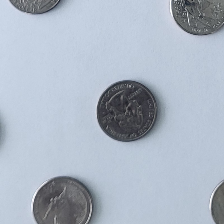

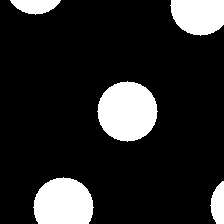

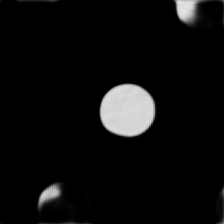

84 0.6219534873962402 tensor(0.) tensor(1.) tensor(7.6923e-17, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.8806, device='cuda:0', grad_fn=<MaxBackward1>)


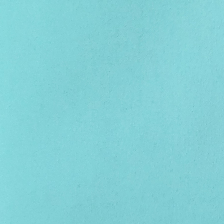

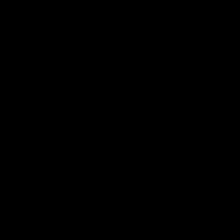

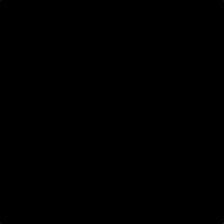

85 0.42781129479408264 tensor(0.) tensor(1.) tensor(3.9053e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.8934, device='cuda:0', grad_fn=<MaxBackward1>)


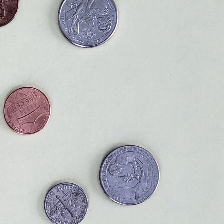

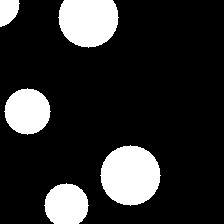

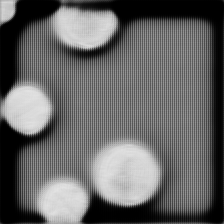

86 0.09801685810089111 tensor(0.) tensor(1.) tensor(2.8694e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7404, device='cuda:0', grad_fn=<MaxBackward1>)


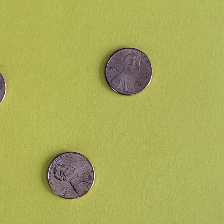

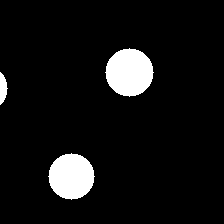

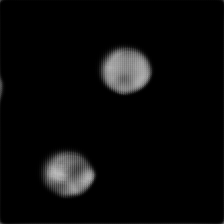

87 0.08095038682222366 tensor(0.) tensor(1.) tensor(2.7884e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.6884, device='cuda:0', grad_fn=<MaxBackward1>)


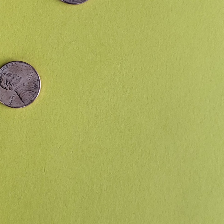

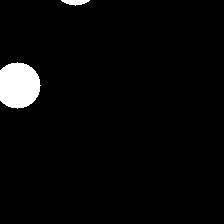

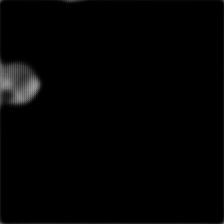

88 0.2039027363061905 tensor(0.) tensor(1.) tensor(0.0002, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7369, device='cuda:0', grad_fn=<MaxBackward1>)


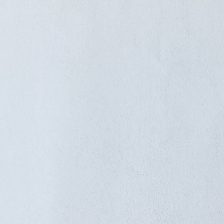

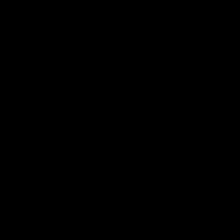

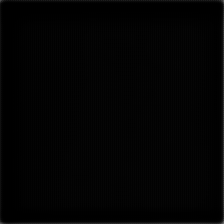

89 0.12050049751996994 tensor(0.) tensor(1.) tensor(0.0031, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7448, device='cuda:0', grad_fn=<MaxBackward1>)


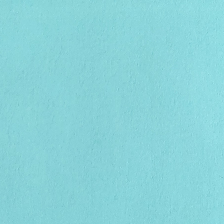

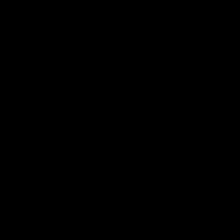

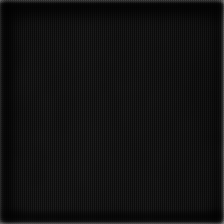

90 0.09429623931646347 tensor(0.) tensor(1.) tensor(0.0052, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.6781, device='cuda:0', grad_fn=<MaxBackward1>)


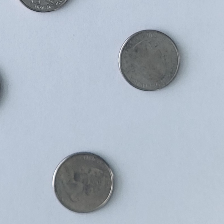

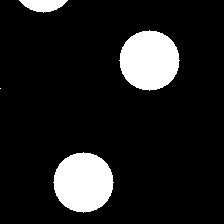

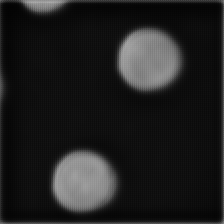

91 0.017321093007922173 tensor(0.) tensor(0.) tensor(0.0021, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.4964, device='cuda:0', grad_fn=<MaxBackward1>)


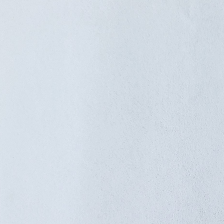

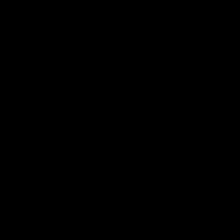

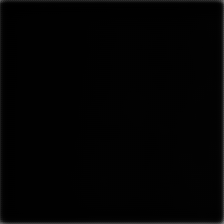

92 0.05690502002835274 tensor(0.) tensor(1.) tensor(0.0008, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7654, device='cuda:0', grad_fn=<MaxBackward1>)


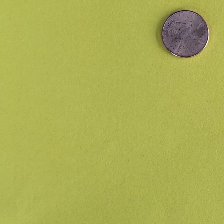

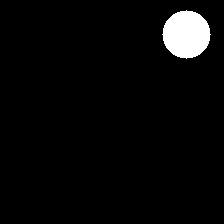

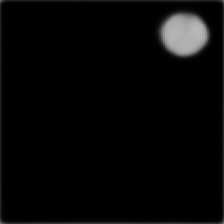

93 0.10237330943346024 tensor(0.) tensor(1.) tensor(0.0012, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7599, device='cuda:0', grad_fn=<MaxBackward1>)


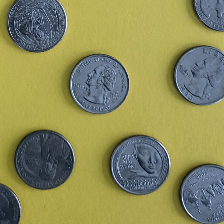

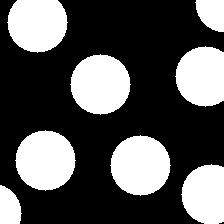

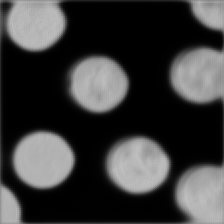

94 0.11251651495695114 tensor(0.) tensor(1.) tensor(0.0021, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7353, device='cuda:0', grad_fn=<MaxBackward1>)


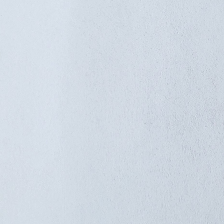

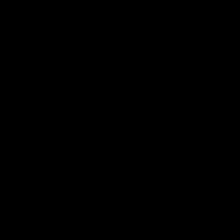

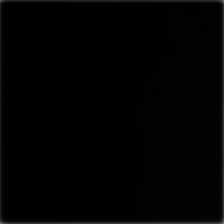

95 0.10359470546245575 tensor(0.) tensor(1.) tensor(0.0011, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7859, device='cuda:0', grad_fn=<MaxBackward1>)


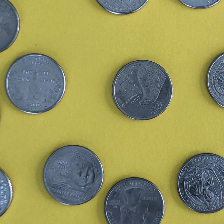

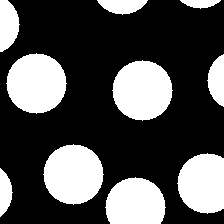

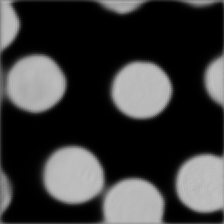

96 0.10031043738126755 tensor(0.) tensor(1.) tensor(0.0011, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7935, device='cuda:0', grad_fn=<MaxBackward1>)


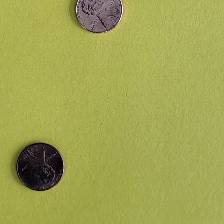

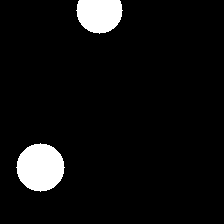

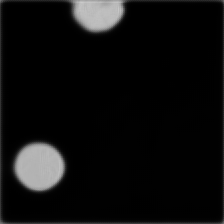

97 0.016897017136216164 tensor(0.) tensor(1.) tensor(0.0005, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7803, device='cuda:0', grad_fn=<MaxBackward1>)


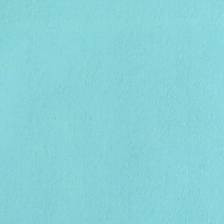

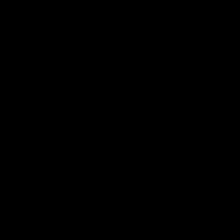

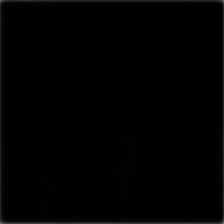

98 0.12988518178462982 tensor(0.) tensor(1.) tensor(0.0006, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7972, device='cuda:0', grad_fn=<MaxBackward1>)


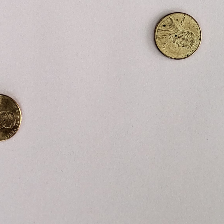

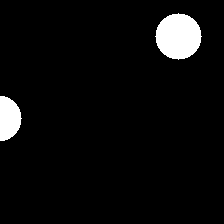

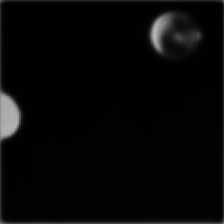

99 0.061645545065402985 tensor(0.) tensor(1.) tensor(0.0015, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.7733, device='cuda:0', grad_fn=<MaxBackward1>)


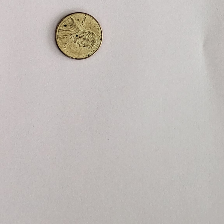

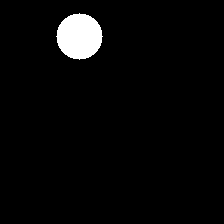

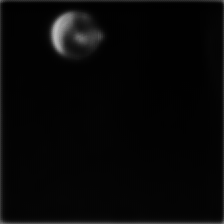

Finished Training


In [ ]:
class Segmentation(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5, padding=2)
        self.conv2 = nn.Conv2d(6, 16, 5, padding=2)
        self.conv3 = nn.Conv2d(16, 32, 5, padding=2)
        self.conv3_5 = nn.Conv2d(32, 32, 5, padding=2)
        self.pool = nn.MaxPool2d(2)
        self.t_conv1 = torch.nn.ConvTranspose2d(32, 32, 4, stride=2, padding=1)
        self.conv4 = nn.Conv2d(64, 16, 5, padding=2)
        self.t_conv2 = torch.nn.ConvTranspose2d(16, 16, 4, stride=2, padding=1)
        self.conv5 = nn.Conv2d(32, 6, 5, padding=2)
        self.t_conv3 = torch.nn.ConvTranspose2d(6, 6, 4, stride=2, padding=1)
        self.conv6 = nn.Conv2d(12, 1, 5, padding=2)

    def forward(self, x):
        #print(x.size())
        x1 = F.relu(self.conv1(x)) # 224x224x6
        #print(x1.size())
        x2 = F.relu(self.conv2(self.pool(x1))) # 112x112x16
        #print(x2.size())
        x3 = F.relu(self.conv3(self.pool(x2))) # 56x56x32
        #print(x3.size())
        x = F.relu(self.conv3_5(self.pool(x3))) # 28x28x32
        #print(x.size())
        tx3 = F.relu(self.t_conv1(x)) # 56x56x32
        #print(x.size())
        x = F.relu(self.conv4(torch.cat((x3,tx3), dim=1))) # 56x56x16
        #print(x.size())
        tx2 = F.relu(self.t_conv2(x)) # 112x112x16
        #print(x.size())
        x = F.relu(self.conv5(torch.cat((x2,tx2), dim=1))) # 112x112x6
        #print(x.size())
        tx1 = F.relu(self.t_conv3(x)) # 224x224x6
        #print(x.size())
        x = torch.sigmoid(self.conv6(torch.cat((x1,tx1), dim=1))) # 224x224x1
        #print(x.size())
        return x

model = Segmentation().cuda()
model.train()

criterion = nn.BCELoss()

"""
for x, y in train_dataloader:
  print(x.shape, y.shape)

  cv2_imshow(x[0].numpy().transpose((1,2,0))*255.0)
  cv2_imshow(y[0,0].numpy()*255.0)

  with torch.no_grad():
    output = model(x.cuda())

  print(output.size())

  break

"""


optimizer = optim.Adam(model.parameters(), lr=0.001)

for i in range(100):
  for x, y in train_dataloader:
    # zero the parameter gradients
    optimizer.zero_grad()

    # forward + backward + optimize
    outputs = model(x.cuda())
    loss = criterion(outputs, y.cuda())
    loss.backward()
    optimizer.step()

  print(i, loss.item(), y.min(), y.max(), outputs.min(), outputs.max())
  cv2_imshow(x[0].numpy().transpose((1,2,0))*255.0)
  cv2_imshow(y[0,0].numpy()*255.0)
  cv2_imshow(outputs[0,0].detach().cpu().numpy()*255.0)

print('Finished Training')

Using cache found in /root/.cache/torch/hub/mateuszbuda_brain-segmentation-pytorch_master


0 0.9543006420135498 tensor(0.) tensor(1.) tensor(1.4476e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


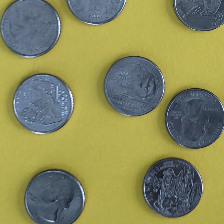

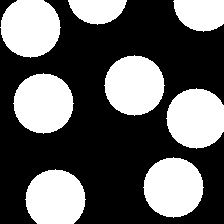

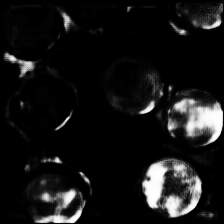

1 0.08608916401863098 tensor(0.) tensor(1.) tensor(5.6803e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(1., device='cuda:0', grad_fn=<MaxBackward1>)


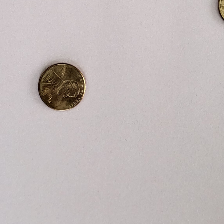

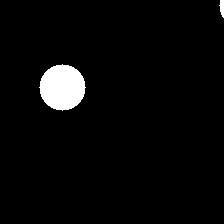

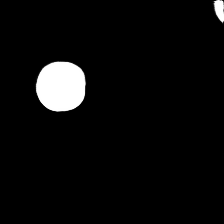

2 0.05649483576416969 tensor(0.) tensor(1.) tensor(3.2602e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


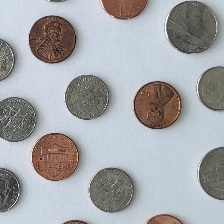

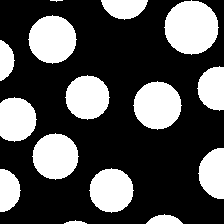

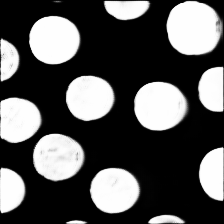

3 0.22472448647022247 tensor(0.) tensor(1.) tensor(2.2418e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


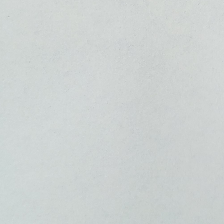

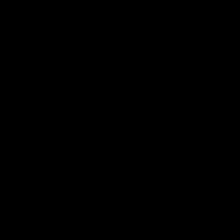

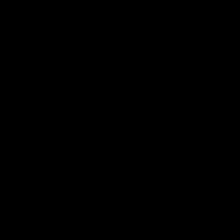

4 0.11238511651754379 tensor(0.) tensor(1.) tensor(4.7331e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1., device='cuda:0', grad_fn=<MaxBackward1>)


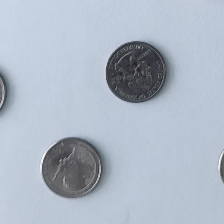

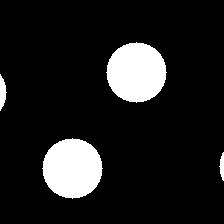

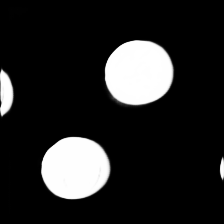

5 0.08606602251529694 tensor(0.) tensor(1.) tensor(6.3837e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


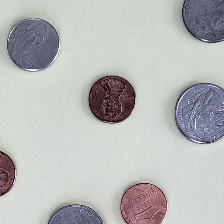

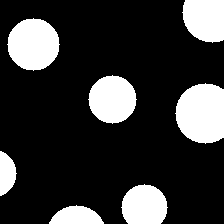

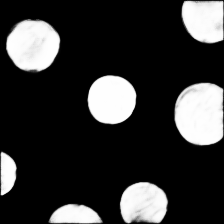

6 0.16192154586315155 tensor(0.) tensor(1.) tensor(7.9791e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(1., device='cuda:0', grad_fn=<MaxBackward1>)


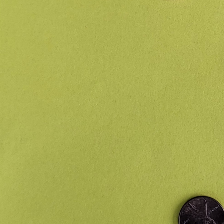

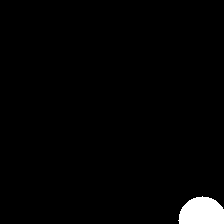

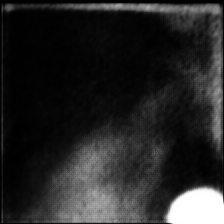

7 0.04729735851287842 tensor(0.) tensor(1.) tensor(2.4695e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


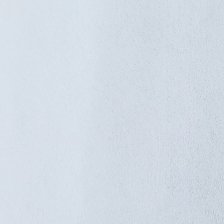

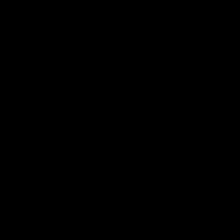

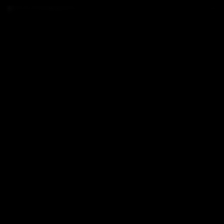

8 0.0527317188680172 tensor(0.) tensor(1.) tensor(8.6327e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


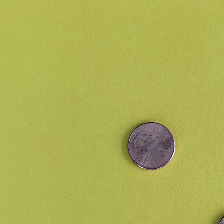

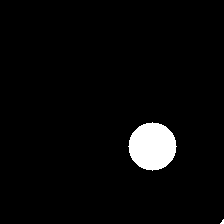

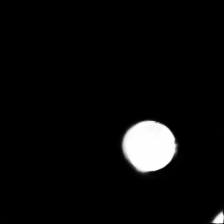

9 0.3342905044555664 tensor(0.) tensor(1.) tensor(3.8451e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9992, device='cuda:0', grad_fn=<MaxBackward1>)


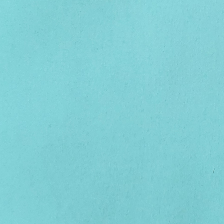

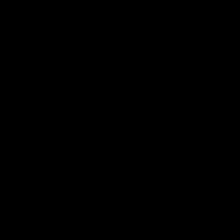

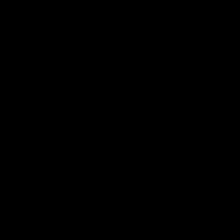

10 0.03476480022072792 tensor(0.) tensor(1.) tensor(6.9521e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


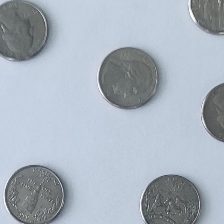

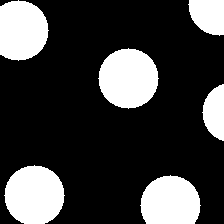

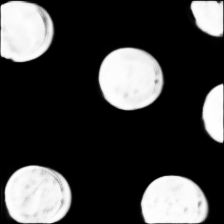

11 0.06499417126178741 tensor(0.) tensor(1.) tensor(4.7748e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9993, device='cuda:0', grad_fn=<MaxBackward1>)


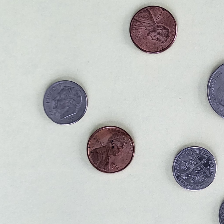

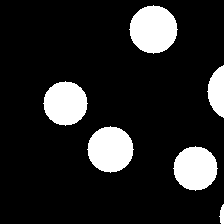

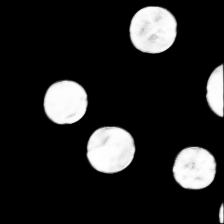

12 0.04417484253644943 tensor(0.) tensor(1.) tensor(4.6663e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9994, device='cuda:0', grad_fn=<MaxBackward1>)


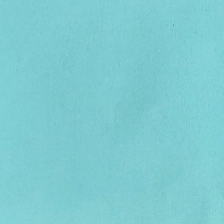

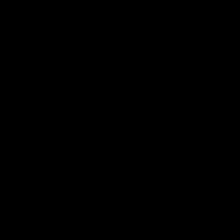

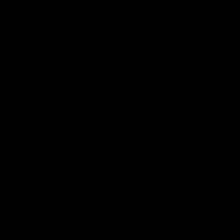

13 0.058523356914520264 tensor(0.) tensor(1.) tensor(5.0315e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9990, device='cuda:0', grad_fn=<MaxBackward1>)


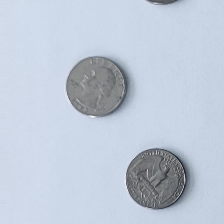

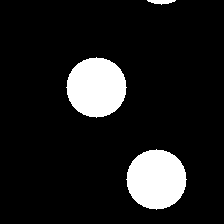

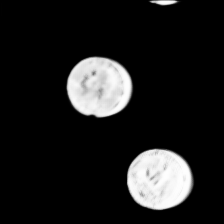

14 0.031715698540210724 tensor(0.) tensor(1.) tensor(1.5311e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9997, device='cuda:0', grad_fn=<MaxBackward1>)


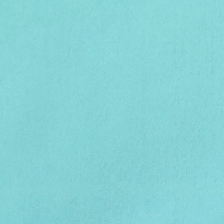

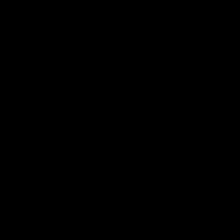

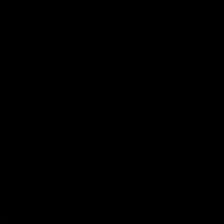

15 0.02939266338944435 tensor(0.) tensor(1.) tensor(1.7173e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9997, device='cuda:0', grad_fn=<MaxBackward1>)


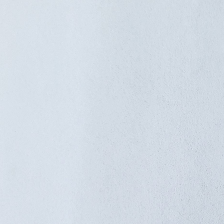

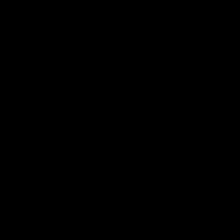

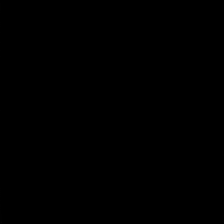

16 0.07848108559846878 tensor(0.) tensor(1.) tensor(1.9129e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9980, device='cuda:0', grad_fn=<MaxBackward1>)


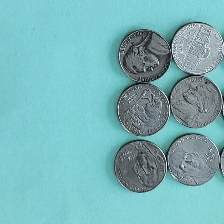

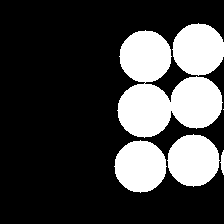

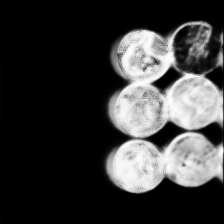

17 0.16919595003128052 tensor(0.) tensor(1.) tensor(7.9235e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9953, device='cuda:0', grad_fn=<MaxBackward1>)


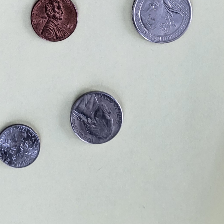

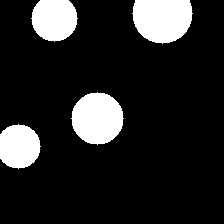

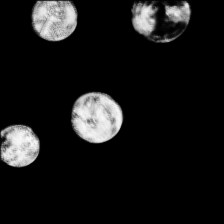

18 0.023121654987335205 tensor(0.) tensor(1.) tensor(3.7513e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9998, device='cuda:0', grad_fn=<MaxBackward1>)


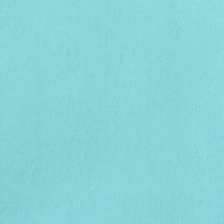

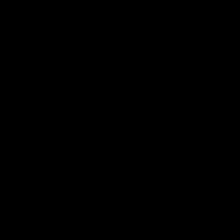

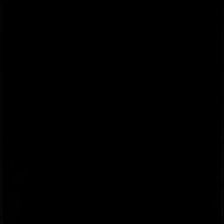

19 0.036896225064992905 tensor(0.) tensor(1.) tensor(1.6884e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


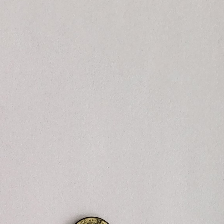

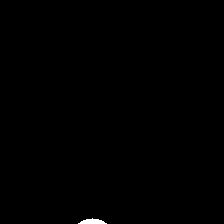

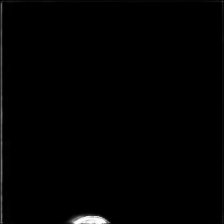

20 0.04320912808179855 tensor(0.) tensor(1.) tensor(2.4358e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9987, device='cuda:0', grad_fn=<MaxBackward1>)


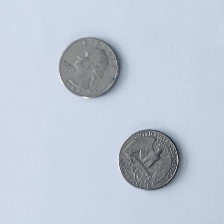

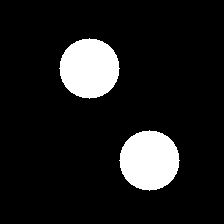

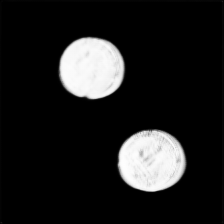

21 0.0766458660364151 tensor(0.) tensor(1.) tensor(2.4751e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9895, device='cuda:0', grad_fn=<MaxBackward1>)


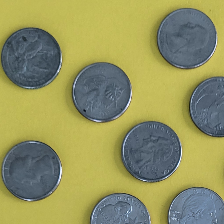

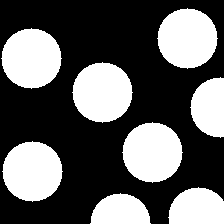

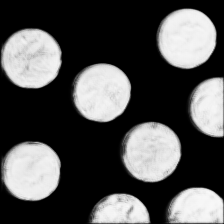

22 0.029696648940443993 tensor(0.) tensor(1.) tensor(7.7643e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


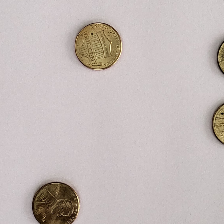

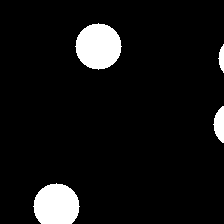

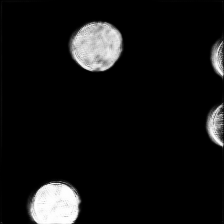

23 0.02203960157930851 tensor(0.) tensor(1.) tensor(5.9790e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9990, device='cuda:0', grad_fn=<MaxBackward1>)


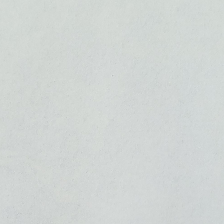

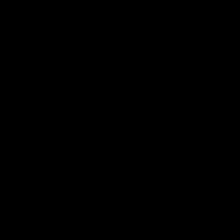

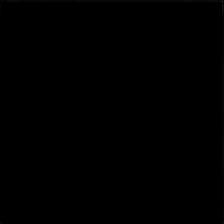

24 0.0598885715007782 tensor(0.) tensor(1.) tensor(3.3548e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9984, device='cuda:0', grad_fn=<MaxBackward1>)


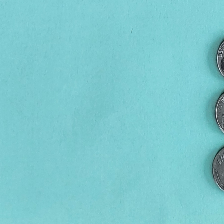

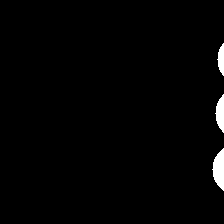

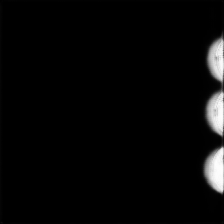

25 0.04165142774581909 tensor(0.) tensor(1.) tensor(3.2387e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9995, device='cuda:0', grad_fn=<MaxBackward1>)


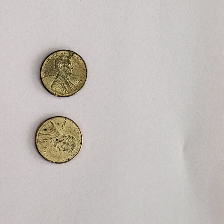

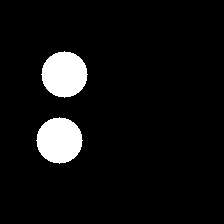

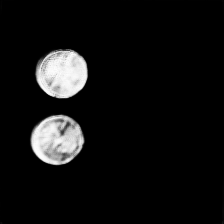

26 0.04688943922519684 tensor(0.) tensor(1.) tensor(8.9144e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9989, device='cuda:0', grad_fn=<MaxBackward1>)


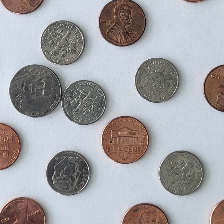

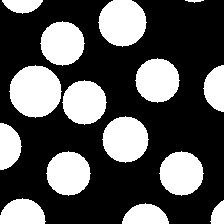

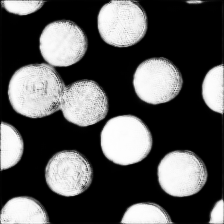

27 0.022193342447280884 tensor(0.) tensor(1.) tensor(1.4184e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


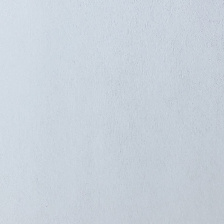

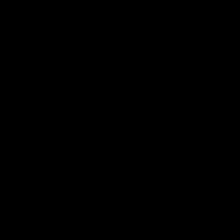

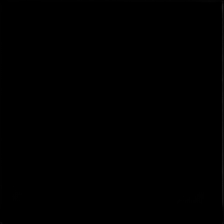

28 0.11186046898365021 tensor(0.) tensor(1.) tensor(1.2272e-10, device='cuda:0', grad_fn=<MinBackward1>) tensor(1., device='cuda:0', grad_fn=<MaxBackward1>)


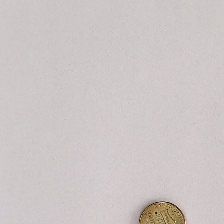

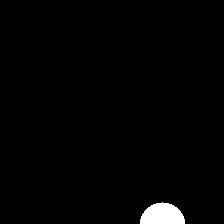

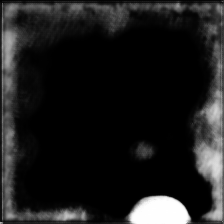

29 0.05194098874926567 tensor(0.) tensor(1.) tensor(2.8268e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


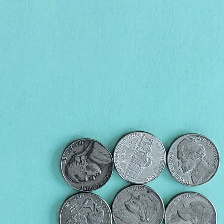

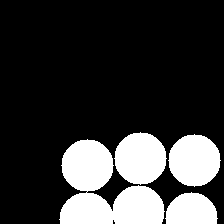

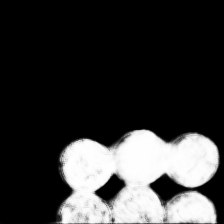

30 0.0461977943778038 tensor(0.) tensor(1.) tensor(1.7561e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


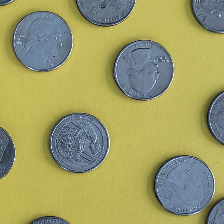

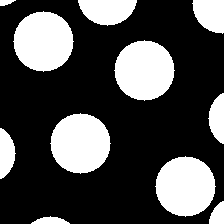

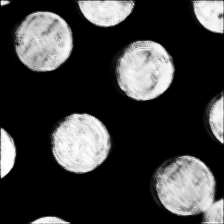

31 0.02370968833565712 tensor(0.) tensor(1.) tensor(4.1688e-10, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


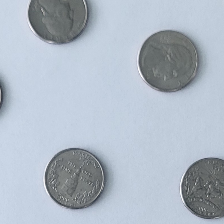

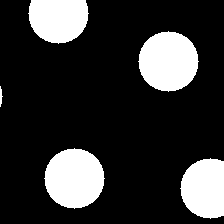

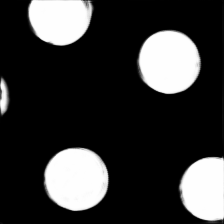

32 0.02889225073158741 tensor(0.) tensor(1.) tensor(1.2276e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


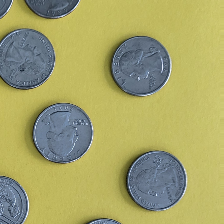

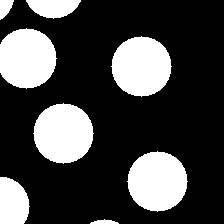

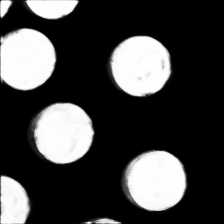

33 0.036145955324172974 tensor(0.) tensor(1.) tensor(6.6938e-10, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


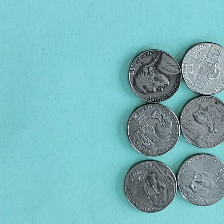

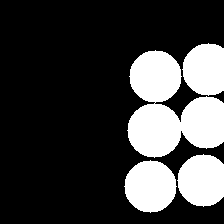

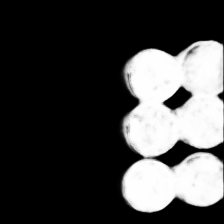

34 0.009412570856511593 tensor(0.) tensor(1.) tensor(5.7225e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


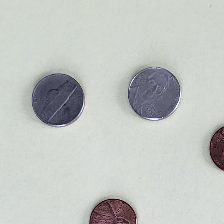

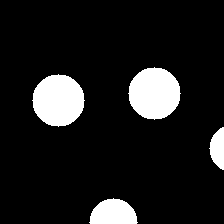

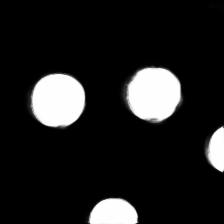

35 0.06233186647295952 tensor(0.) tensor(1.) tensor(5.8595e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9998, device='cuda:0', grad_fn=<MaxBackward1>)


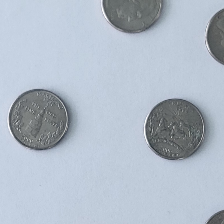

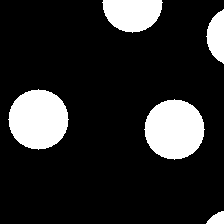

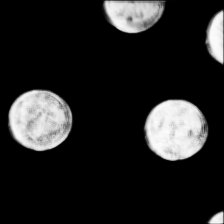

36 0.028895342722535133 tensor(0.) tensor(1.) tensor(1.8379e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1., device='cuda:0', grad_fn=<MaxBackward1>)


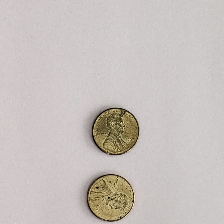

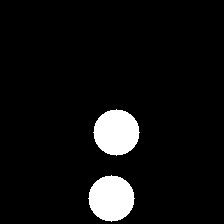

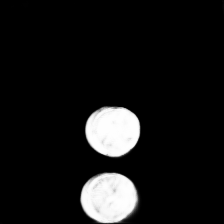

37 0.014218011870980263 tensor(0.) tensor(1.) tensor(6.3477e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


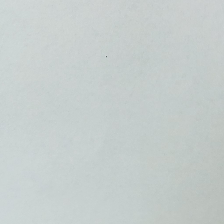

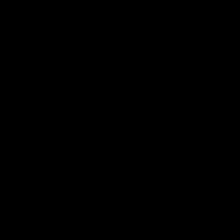

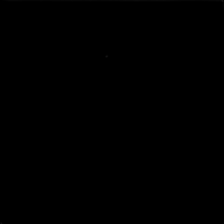

38 0.05414310470223427 tensor(0.) tensor(1.) tensor(9.5110e-10, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9963, device='cuda:0', grad_fn=<MaxBackward1>)


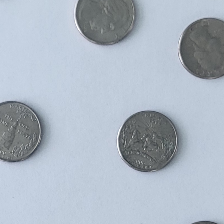

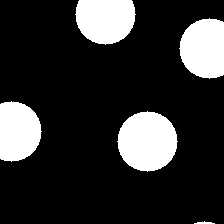

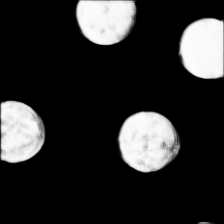

39 0.03699945658445358 tensor(0.) tensor(1.) tensor(3.2310e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


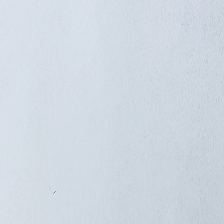

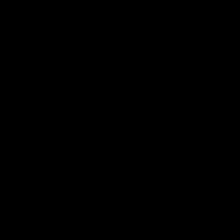

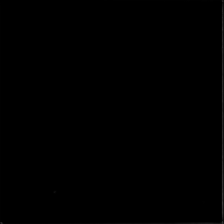

40 0.03773541748523712 tensor(0.) tensor(1.) tensor(2.4331e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9998, device='cuda:0', grad_fn=<MaxBackward1>)


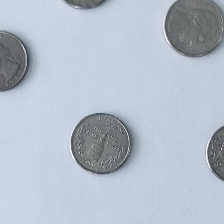

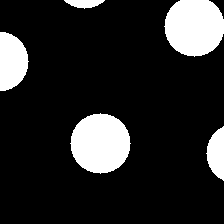

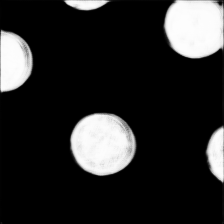

41 0.01680668443441391 tensor(0.) tensor(1.) tensor(3.1917e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9985, device='cuda:0', grad_fn=<MaxBackward1>)


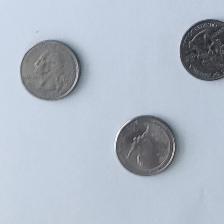

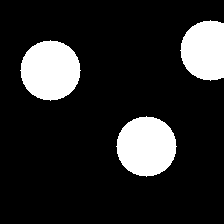

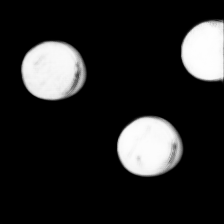

42 0.04126022011041641 tensor(0.) tensor(1.) tensor(1.0551e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9995, device='cuda:0', grad_fn=<MaxBackward1>)


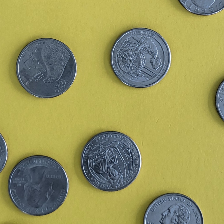

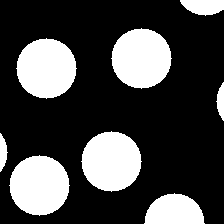

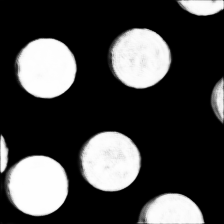

43 0.023935353383421898 tensor(0.) tensor(1.) tensor(1.1260e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


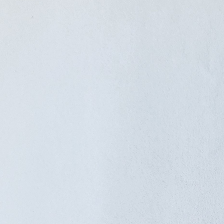

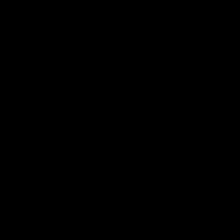

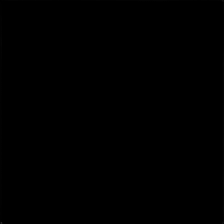

44 0.02136177383363247 tensor(0.) tensor(1.) tensor(1.1163e-10, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


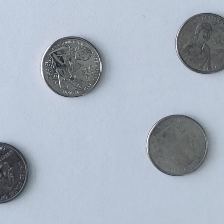

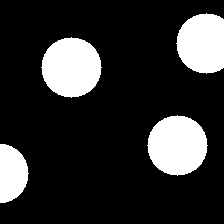

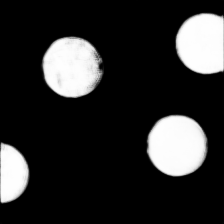

45 0.031827230006456375 tensor(0.) tensor(1.) tensor(1.7557e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


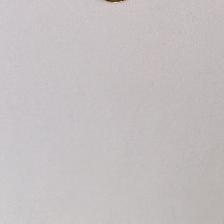

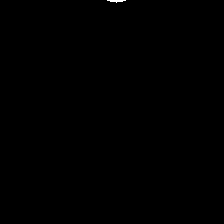

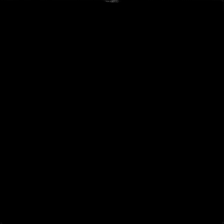

46 0.22577594220638275 tensor(0.) tensor(0.) tensor(4.9820e-11, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9884, device='cuda:0', grad_fn=<MaxBackward1>)


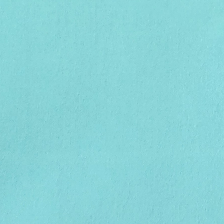

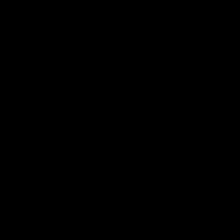

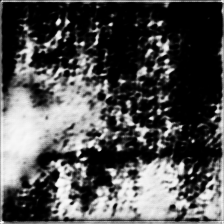

47 0.03975610435009003 tensor(0.) tensor(1.) tensor(1.1249e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9996, device='cuda:0', grad_fn=<MaxBackward1>)


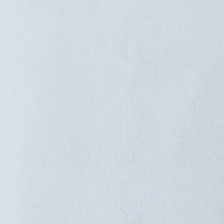

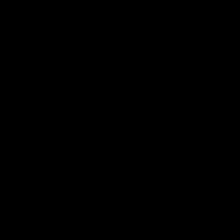

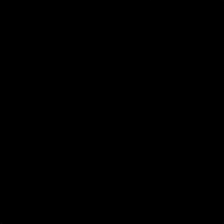

48 0.015261663123965263 tensor(0.) tensor(1.) tensor(1.4790e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


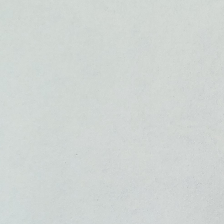

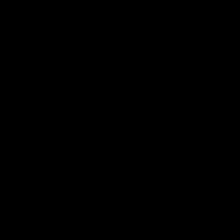

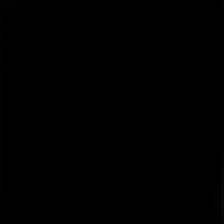

49 0.01740984059870243 tensor(0.) tensor(1.) tensor(1.8361e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


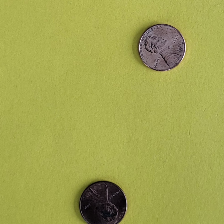

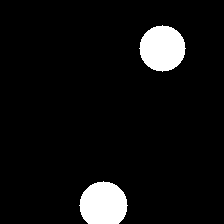

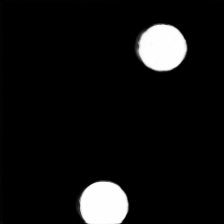

50 0.2977893650531769 tensor(0.) tensor(0.) tensor(1.7109e-10, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9994, device='cuda:0', grad_fn=<MaxBackward1>)


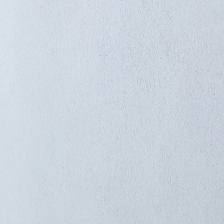

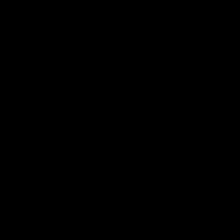

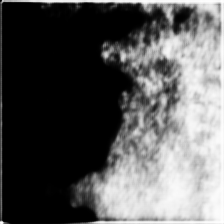

51 0.026417234912514687 tensor(0.) tensor(1.) tensor(2.0421e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9890, device='cuda:0', grad_fn=<MaxBackward1>)


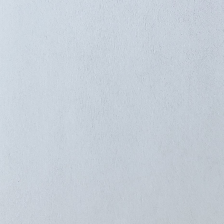

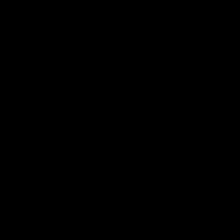

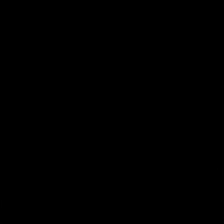

52 0.1705484837293625 tensor(0.) tensor(1.) tensor(1.2440e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9975, device='cuda:0', grad_fn=<MaxBackward1>)


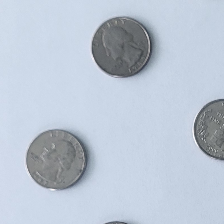

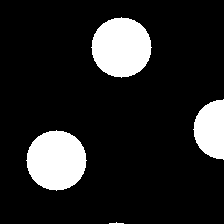

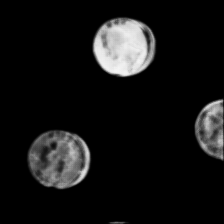

53 0.01893731765449047 tensor(0.) tensor(1.) tensor(1.7765e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


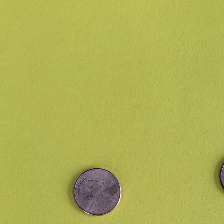

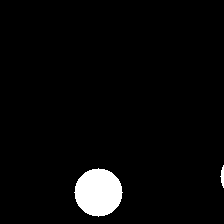

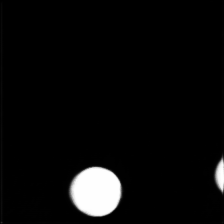

54 0.08242152631282806 tensor(0.) tensor(1.) tensor(3.4224e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


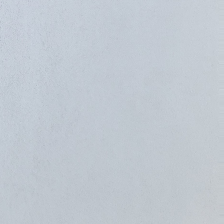

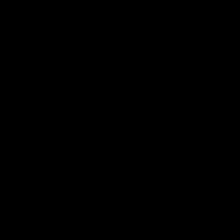

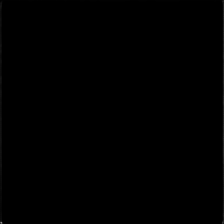

55 0.04352748021483421 tensor(0.) tensor(1.) tensor(5.7084e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9998, device='cuda:0', grad_fn=<MaxBackward1>)


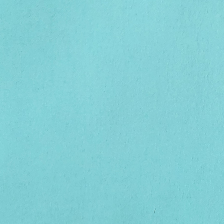

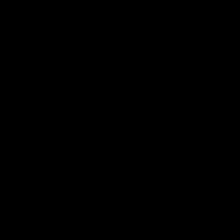

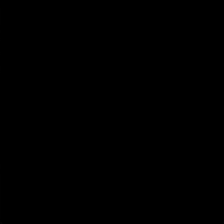

56 0.09555275738239288 tensor(0.) tensor(1.) tensor(8.3684e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


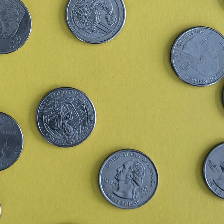

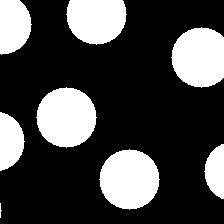

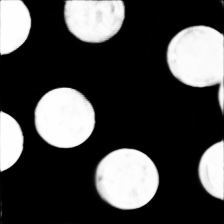

57 0.037407297641038895 tensor(0.) tensor(1.) tensor(1.4393e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


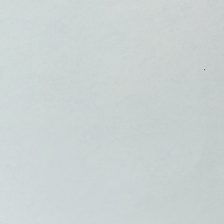

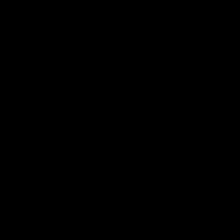

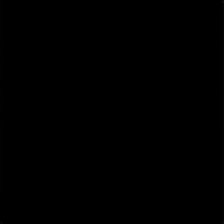

58 0.04911288246512413 tensor(0.) tensor(1.) tensor(6.2161e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9981, device='cuda:0', grad_fn=<MaxBackward1>)


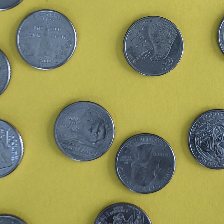

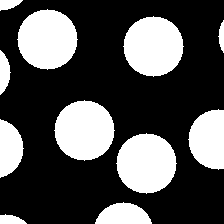

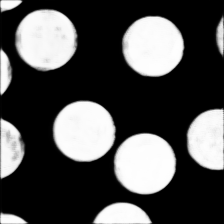

59 0.04513664171099663 tensor(0.) tensor(1.) tensor(8.3966e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9985, device='cuda:0', grad_fn=<MaxBackward1>)


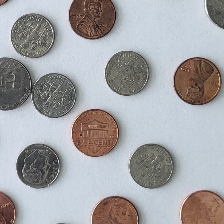

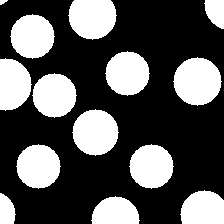

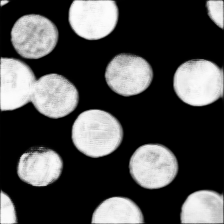

60 0.03496086224913597 tensor(0.) tensor(1.) tensor(6.0155e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9961, device='cuda:0', grad_fn=<MaxBackward1>)


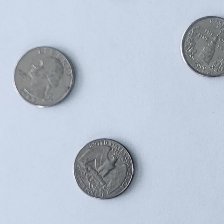

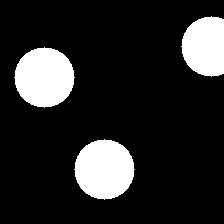

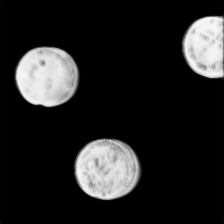

61 0.006354894954711199 tensor(0.) tensor(0.) tensor(6.0638e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.8463, device='cuda:0', grad_fn=<MaxBackward1>)


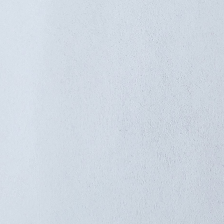

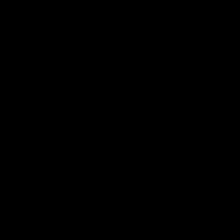

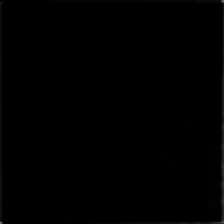

62 0.047902125865221024 tensor(0.) tensor(1.) tensor(2.7518e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9983, device='cuda:0', grad_fn=<MaxBackward1>)


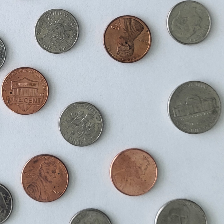

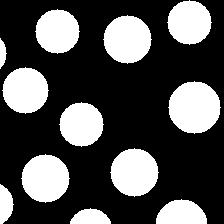

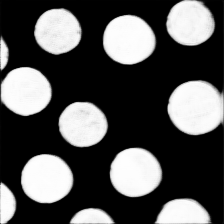

63 0.09579471498727798 tensor(0.) tensor(1.) tensor(8.6570e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


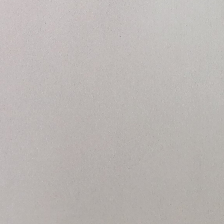

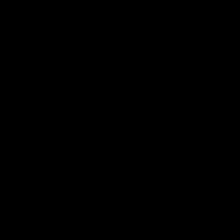

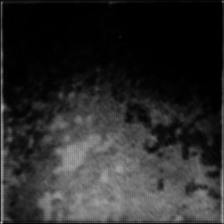

64 0.045408520847558975 tensor(0.) tensor(1.) tensor(1.4547e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9993, device='cuda:0', grad_fn=<MaxBackward1>)


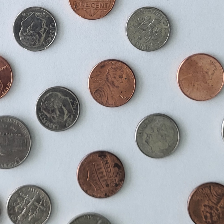

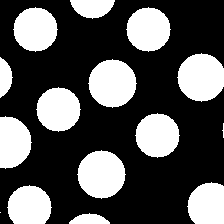

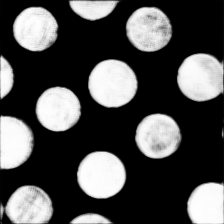

65 0.045339297503232956 tensor(0.) tensor(1.) tensor(1.0148e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


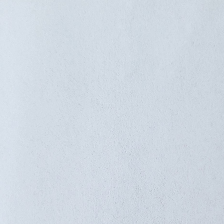

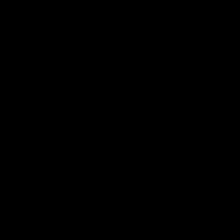

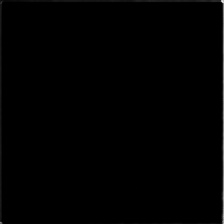

66 0.02862415835261345 tensor(0.) tensor(1.) tensor(1.8088e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9987, device='cuda:0', grad_fn=<MaxBackward1>)


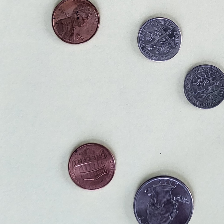

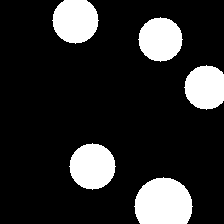

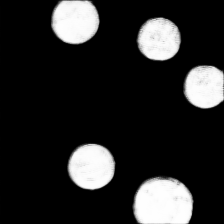

67 0.021453727036714554 tensor(0.) tensor(1.) tensor(4.0020e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9997, device='cuda:0', grad_fn=<MaxBackward1>)


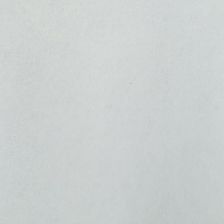

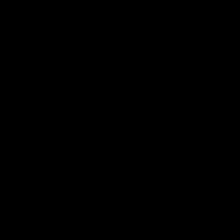

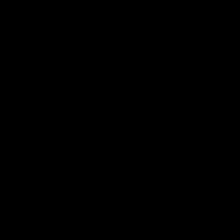

68 0.0237995944917202 tensor(0.) tensor(1.) tensor(5.6420e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


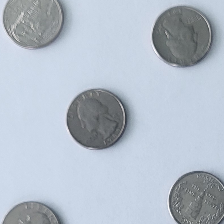

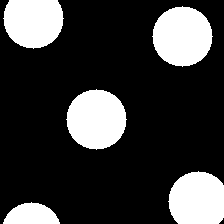

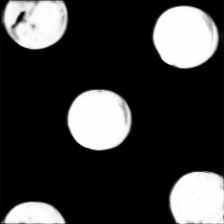

69 0.06601075828075409 tensor(0.) tensor(1.) tensor(1.3349e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9992, device='cuda:0', grad_fn=<MaxBackward1>)


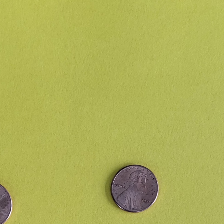

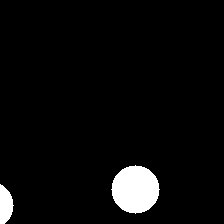

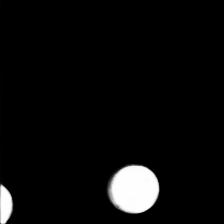

70 0.01488106232136488 tensor(0.) tensor(1.) tensor(7.7593e-10, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9979, device='cuda:0', grad_fn=<MaxBackward1>)


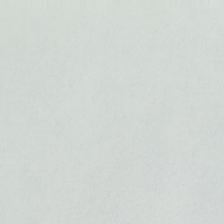

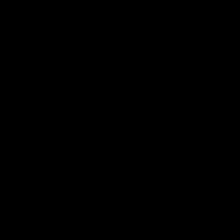

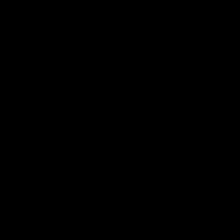

71 0.033690281212329865 tensor(0.) tensor(1.) tensor(1.7465e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9994, device='cuda:0', grad_fn=<MaxBackward1>)


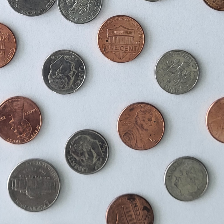

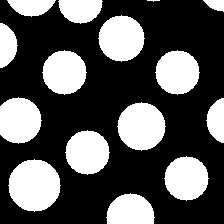

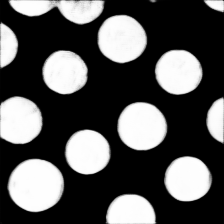

72 0.003503231331706047 tensor(0.) tensor(1.) tensor(9.6446e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


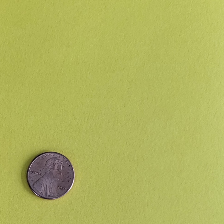

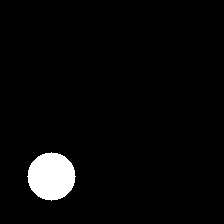

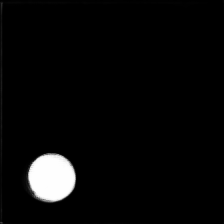

73 0.030772428959608078 tensor(0.) tensor(1.) tensor(2.8022e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9998, device='cuda:0', grad_fn=<MaxBackward1>)


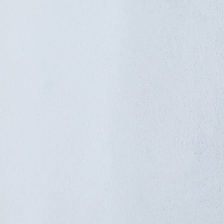

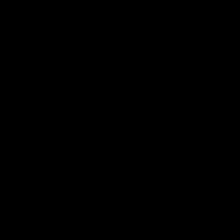

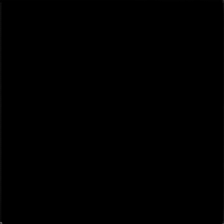

74 0.01965373195707798 tensor(0.) tensor(1.) tensor(8.1847e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9987, device='cuda:0', grad_fn=<MaxBackward1>)


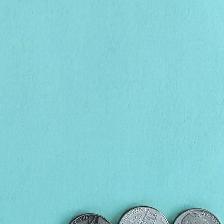

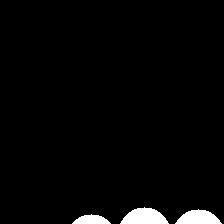

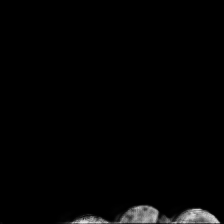

75 0.010571202263236046 tensor(0.) tensor(1.) tensor(3.2510e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


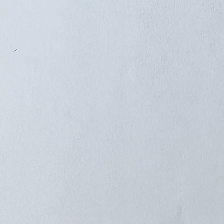

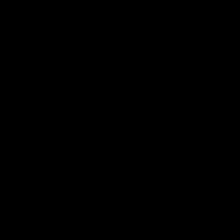

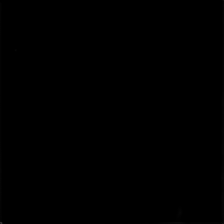

76 0.016751332208514214 tensor(0.) tensor(1.) tensor(1.3418e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9997, device='cuda:0', grad_fn=<MaxBackward1>)


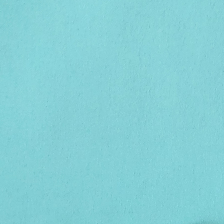

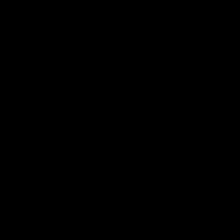

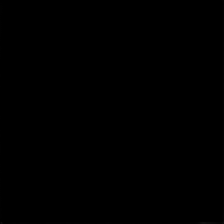

77 0.021866450086236 tensor(0.) tensor(1.) tensor(4.7401e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


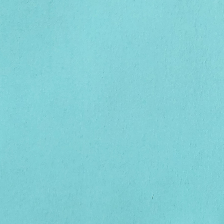

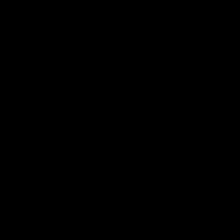

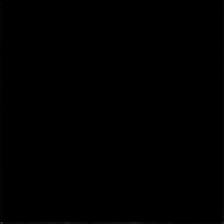

78 0.021317895501852036 tensor(0.) tensor(1.) tensor(1.2521e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


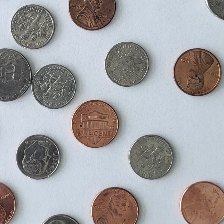

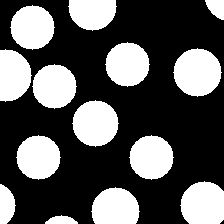

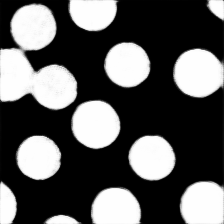

79 0.05814247205853462 tensor(0.) tensor(1.) tensor(8.5103e-10, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9994, device='cuda:0', grad_fn=<MaxBackward1>)


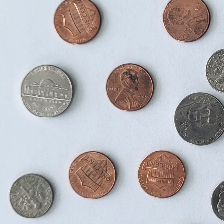

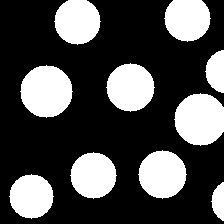

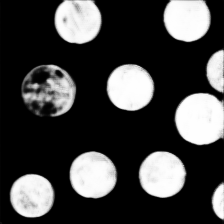

80 0.0455256849527359 tensor(0.) tensor(1.) tensor(4.1396e-10, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


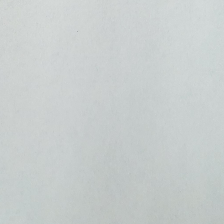

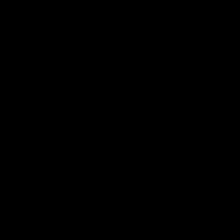

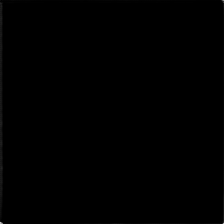

81 0.016799310222268105 tensor(0.) tensor(1.) tensor(1.4678e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


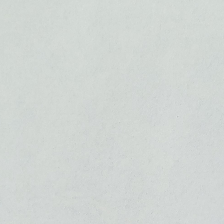

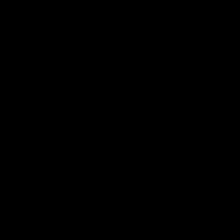

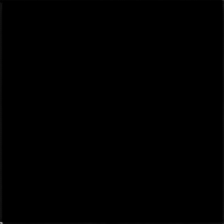

82 0.0274263434112072 tensor(0.) tensor(1.) tensor(1.2673e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


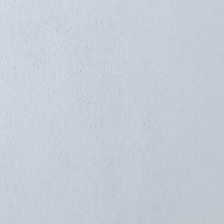

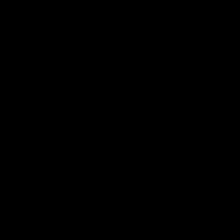

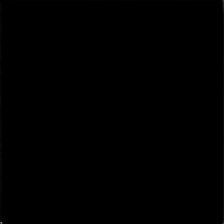

83 0.008250268176198006 tensor(0.) tensor(1.) tensor(2.0366e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


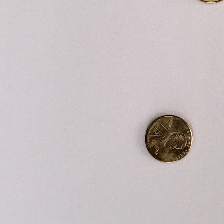

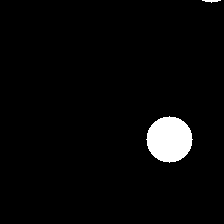

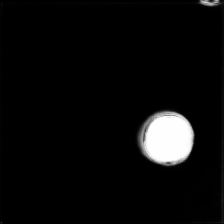

84 0.015498003922402859 tensor(0.) tensor(1.) tensor(5.1866e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


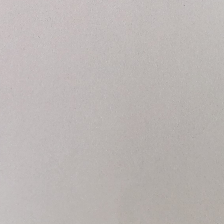

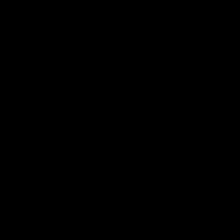

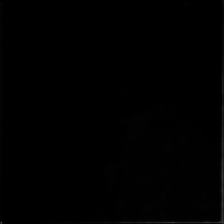

85 0.042639512568712234 tensor(0.) tensor(1.) tensor(7.3226e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


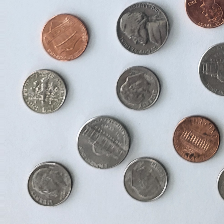

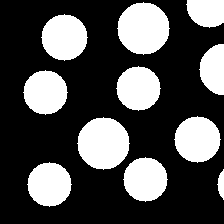

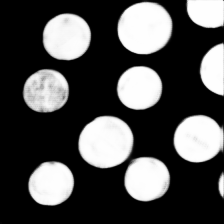

86 0.013839979656040668 tensor(0.) tensor(1.) tensor(3.0077e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


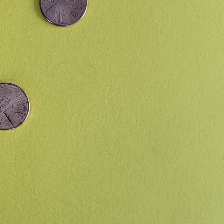

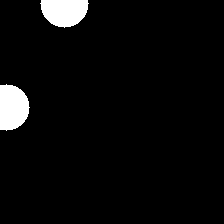

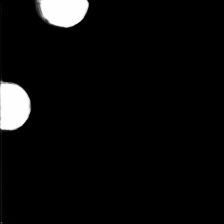

87 0.025454584509134293 tensor(0.) tensor(1.) tensor(3.7090e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


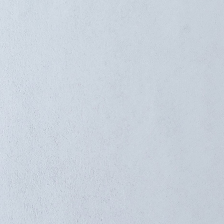

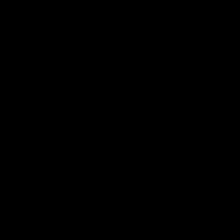

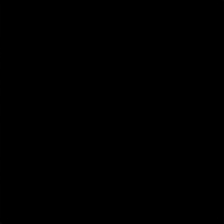

88 0.017196733504533768 tensor(0.) tensor(1.) tensor(4.3069e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9996, device='cuda:0', grad_fn=<MaxBackward1>)


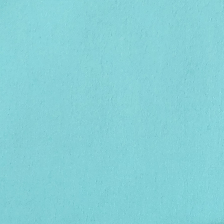

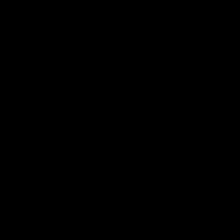

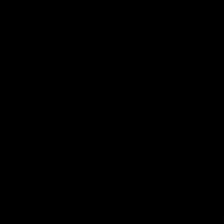

89 0.01859528385102749 tensor(0.) tensor(1.) tensor(7.9638e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9996, device='cuda:0', grad_fn=<MaxBackward1>)


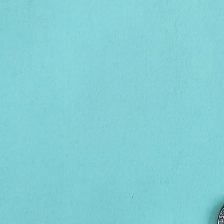

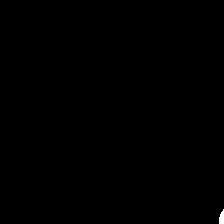

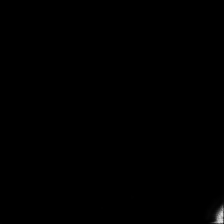

90 0.03619137406349182 tensor(0.) tensor(1.) tensor(2.7086e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9998, device='cuda:0', grad_fn=<MaxBackward1>)


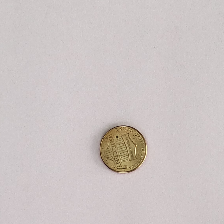

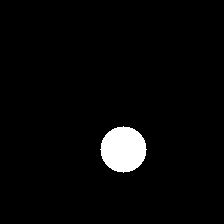

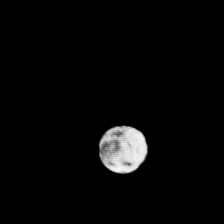

91 0.014286424033343792 tensor(0.) tensor(1.) tensor(3.8572e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9997, device='cuda:0', grad_fn=<MaxBackward1>)


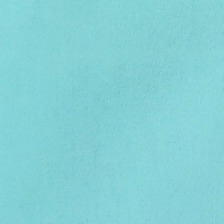

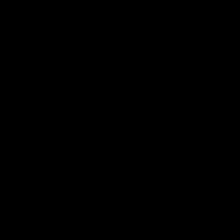

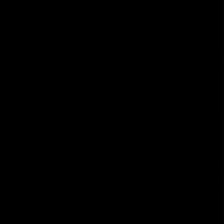

92 0.011906187050044537 tensor(0.) tensor(1.) tensor(4.1313e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


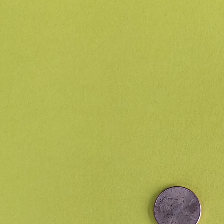

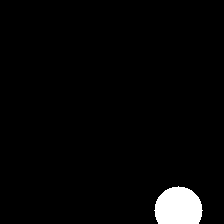

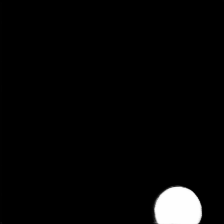

93 0.029383350163698196 tensor(0.) tensor(1.) tensor(1.7147e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


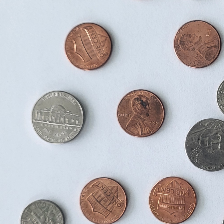

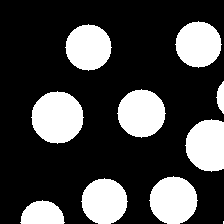

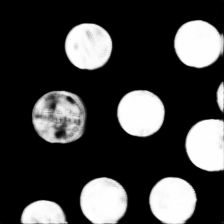

94 0.00980890542268753 tensor(0.) tensor(1.) tensor(6.4672e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


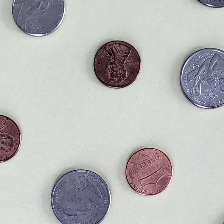

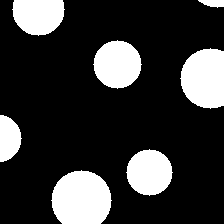

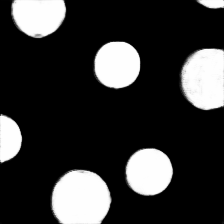

95 0.00840105302631855 tensor(0.) tensor(1.) tensor(3.7712e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1., device='cuda:0', grad_fn=<MaxBackward1>)


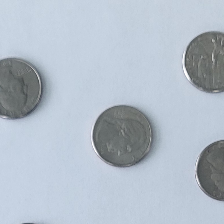

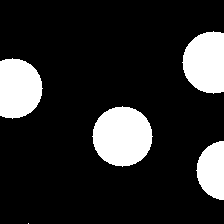

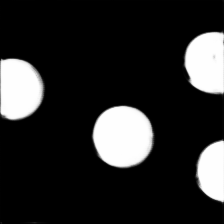

96 0.0116342194378376 tensor(0.) tensor(1.) tensor(8.0957e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


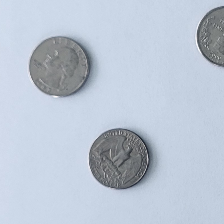

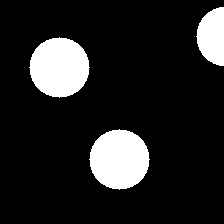

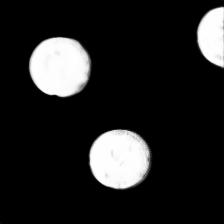

97 0.01342215295881033 tensor(0.) tensor(1.) tensor(3.2141e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


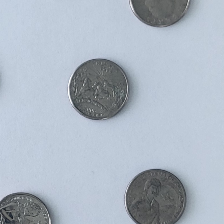

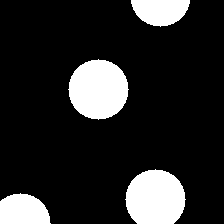

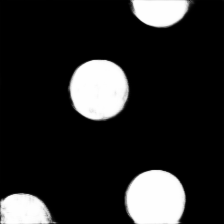

98 0.018585963174700737 tensor(0.) tensor(1.) tensor(1.9546e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


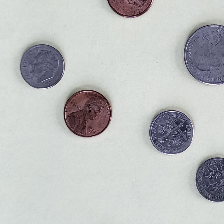

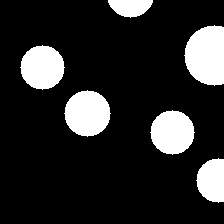

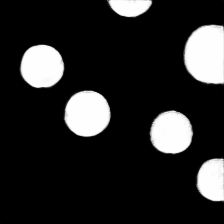

99 0.02546827681362629 tensor(0.) tensor(1.) tensor(6.6723e-09, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


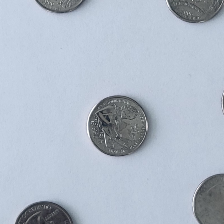

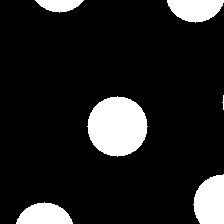

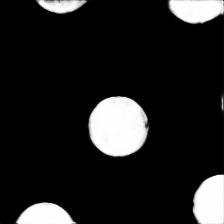

Finished Training


In [ ]:
model = torch.hub.load('mateuszbuda/brain-segmentation-pytorch', 'unet', in_channels=3, out_channels=1, init_features=32, pretrained=True)
model = model.cuda()

criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

model.train()
for i in range(100):
  for x, y in train_dataloader:
    # zero the parameter gradients
    optimizer.zero_grad()

    # forward + backward + optimize
    outputs = model(x.cuda())
    loss = criterion(outputs, y.cuda())
    loss.backward()
    optimizer.step()

  print(i, loss.item(), y.min(), y.max(), outputs.min(), outputs.max())
  cv2_imshow(x[0].numpy().transpose((1,2,0))*255.0)
  cv2_imshow(y[0,0].numpy()*255.0)
  cv2_imshow(outputs[0,0].detach().cpu().numpy()*255.0)

print('Finished Training')

9
torch.Size([3, 3, 224, 224]) torch.FloatTensor torch.Size([3, 224, 224]) torch.LongTensor


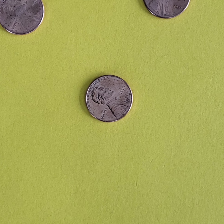

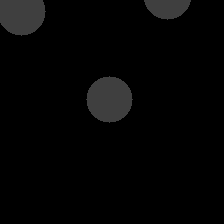

In [ ]:
class SemanticCoins(torch.utils.data.Dataset):
    def __init__(self, path, mode):
        self.path = path
        self.images = sorted([x for x in os.listdir(path) if x.endswith('.png')])
        self.mode = mode

        self.t_train = transforms.Compose([
            torchvision.transforms.RandomCrop((224,224))
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = cv2.imread(os.path.join(self.path, self.images[idx]), cv2.IMREAD_COLOR)
        img = cv2.resize(img, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_LINEAR)
        h, w, _ = img.shape
        img = img/255.0
        img = np.transpose(img, (2,0,1)).astype(np.float32)
        img = torch.from_numpy(img)

        with open(os.path.join(self.path, self.images[idx].replace('.png', '.txt')), 'r') as fp:
            lines = fp.readlines()

        mask = np.zeros((img.size(1), img.size(2)), np.uint8)
        for line in lines[1:]:
            x, y, val, r = [int(x) for x in line.split()]
            x = int(x*0.25+0.5)
            y = int(y*0.25+0.5)
            r = int(r*0.25+0.5)
            if val==1:
              cv2.circle(mask, (x, y), r, (1,1,1), -1)
            elif val==5:
              cv2.circle(mask, (x, y), r, (2,2,2), -1)
            elif val==10:
              cv2.circle(mask, (x, y), r, (3,3,3), -1)
            elif val==25:
              cv2.circle(mask, (x, y), r, (4,4,4), -1)

        mask = mask.astype(np.int64)
        mask = torch.from_numpy(mask)

        if self.mode == 'train':
          dx = torch.randint(low=0, high=w-224, size=(1,)).item()
          dy = torch.randint(low=0, high=h-224, size=(1,)).item()
          img = img[:, dy:dy+224, dx:dx+224]
          mask = mask[dy:dy+224, dx:dx+224]

        return img, mask

train_dataset = SemanticCoins('/content/drive/MyDrive/ComputerVision/coins', 'train')
print(len(train_dataset))
#val_dataset = CIFAR(x_train[4000:], y_train[4000:], 'val')
train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=3, shuffle=True)
#val_dataloader = torch.utils.data.DataLoader(val_dataset, batch_size=100, shuffle=False)

for x, y in train_dataloader:
  print(x.shape, x.type(), y.shape, y.type())

  cv2_imshow(x[0].numpy().transpose((1,2,0))*255.0)

  #array = [y[0,i].numpy()*255.0 for i in range(5)]
  #img = np.concatenate(array, axis=1)
  #print(img.shape)
  cv2_imshow(y[0].numpy()*63.0)

  break

Using cache found in /root/.cache/torch/hub/mateuszbuda_brain-segmentation-pytorch_master


99 0.9886617660522461 tensor(0) tensor(4) tensor(0.0003, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9993, device='cuda:0', grad_fn=<MaxBackward1>)


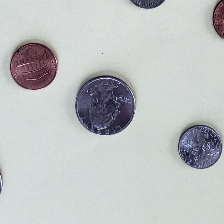

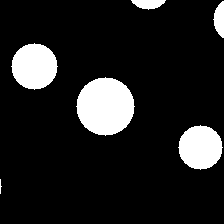

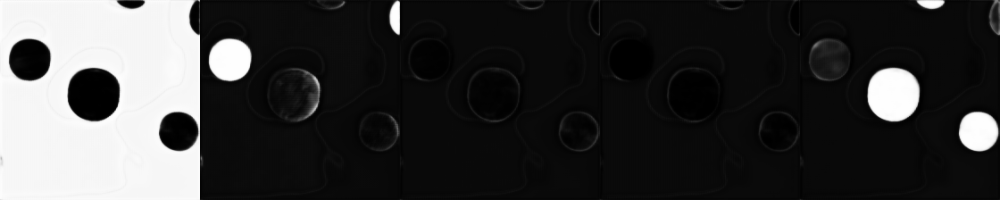

199 0.9250949025154114 tensor(0) tensor(4) tensor(1.1785e-05, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


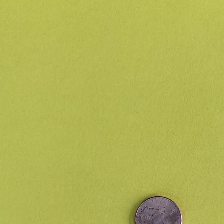

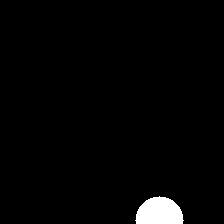

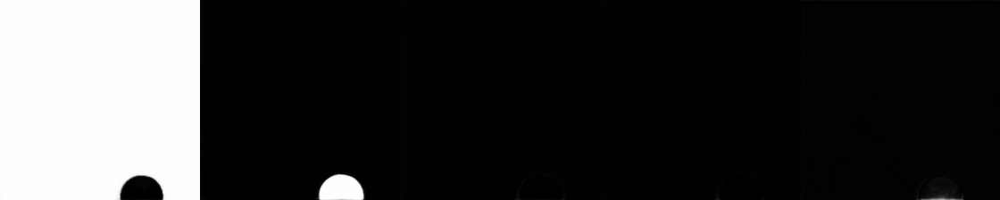

299 0.9139041900634766 tensor(0) tensor(4) tensor(9.5511e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(0.9999, device='cuda:0', grad_fn=<MaxBackward1>)


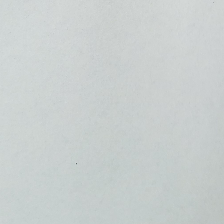

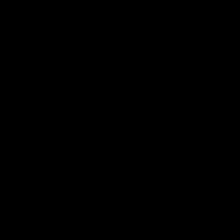

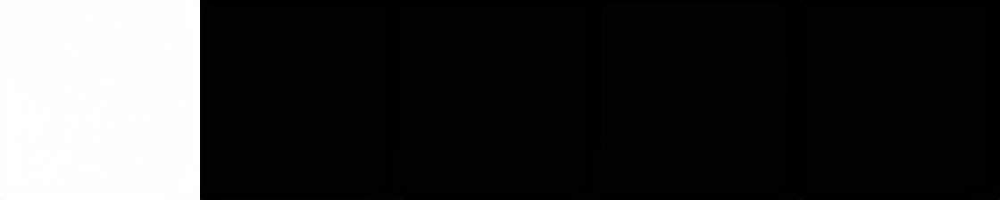

399 0.9726892709732056 tensor(0) tensor(4) tensor(5.3736e-06, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


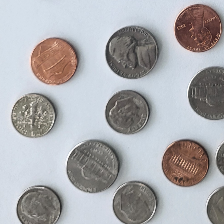

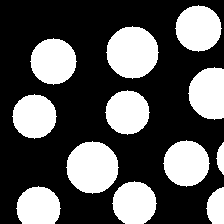

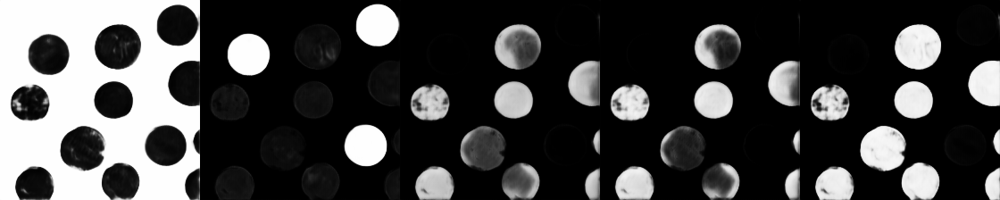

499 0.9163957238197327 tensor(0) tensor(4) tensor(4.9861e-11, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


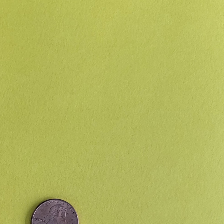

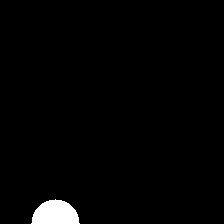

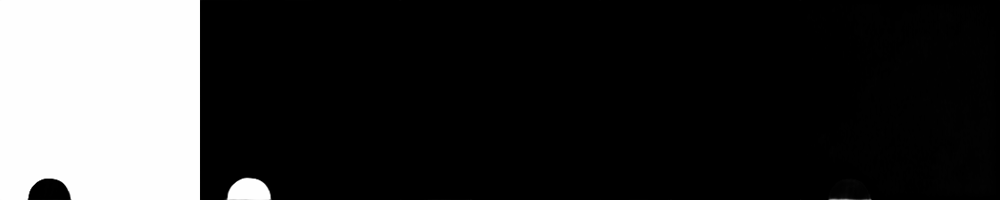

599 0.9066569209098816 tensor(0) tensor(1) tensor(5.4446e-23, device='cuda:0', grad_fn=<MinBackward1>) tensor(1., device='cuda:0', grad_fn=<MaxBackward1>)


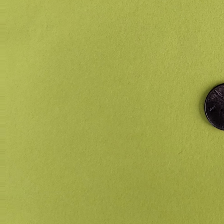

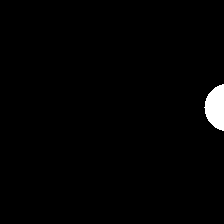

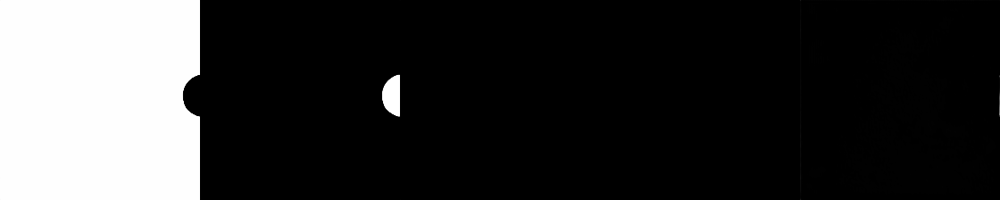

699 0.9374604225158691 tensor(0) tensor(4) tensor(9.0773e-10, device='cuda:0', grad_fn=<MinBackward1>) tensor(1., device='cuda:0', grad_fn=<MaxBackward1>)


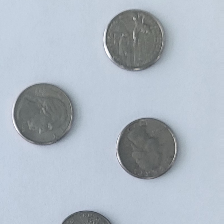

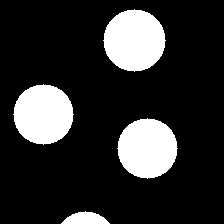

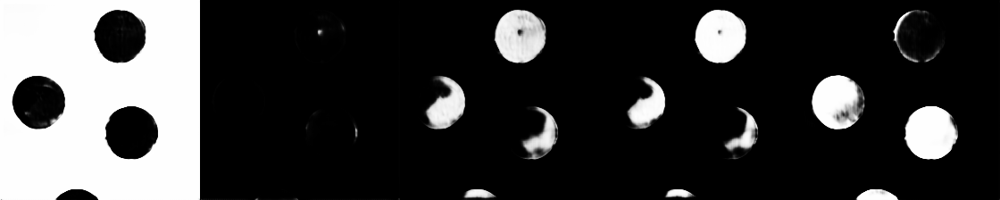

799 0.912141740322113 tensor(0) tensor(4) tensor(7.6524e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


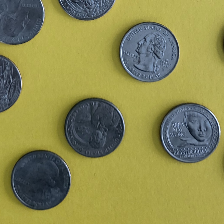

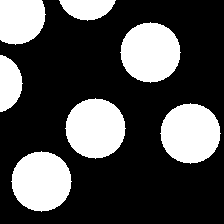

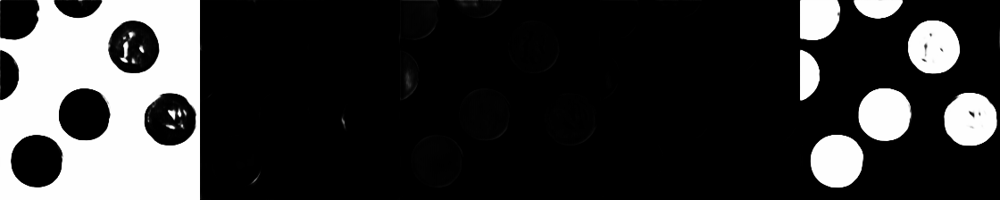

899 0.909876823425293 tensor(0) tensor(4) tensor(1.0362e-07, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


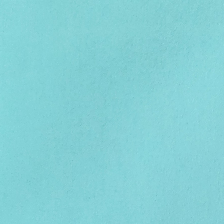

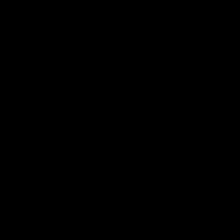

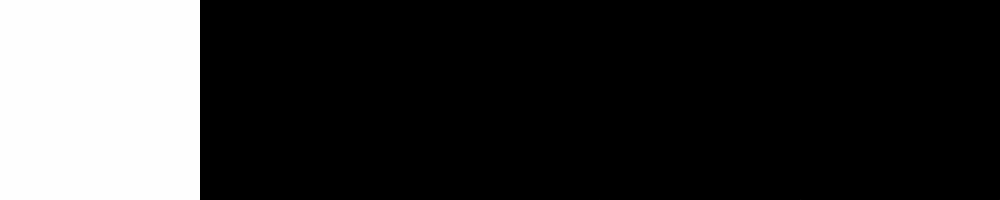

999 0.9093683958053589 tensor(0) tensor(4) tensor(4.2324e-08, device='cuda:0', grad_fn=<MinBackward1>) tensor(1.0000, device='cuda:0', grad_fn=<MaxBackward1>)


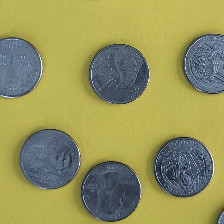

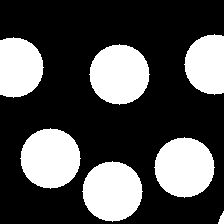

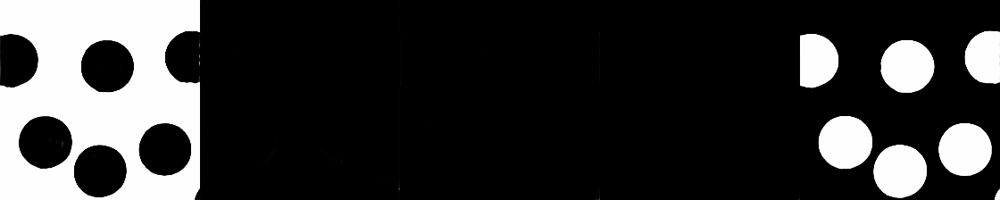

Finished Training


In [ ]:
model = torch.hub.load('mateuszbuda/brain-segmentation-pytorch', 'unet', in_channels=3, out_channels=5, init_features=32, pretrained=False)
model = model.cuda()

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

model.train()
for i in range(1000):
  for x, y in train_dataloader:
    # zero the parameter gradients
    optimizer.zero_grad()

    # forward + backward + optimize
    outputs = model(x.cuda())
    loss = criterion(outputs, y.cuda())
    loss.backward()
    optimizer.step()

  if i%100 == 99:
    print(i, loss.item(), y.min(), y.max(), outputs.min(), outputs.max())
    cv2_imshow(x[0].numpy().transpose((1,2,0))*255.0)
    cv2_imshow(y[0].numpy()*255.0)
    img = [outputs[0,i].detach().cpu().numpy()*255.0 for i in range(5)]
    img = np.concatenate(img, axis=1)
    cv2_imshow(img)

print('Finished Training')